# Results for the paper

### Evaluation of SWOT-Derived Surface Geostrophic Currents Using HF Radar Observations in the Southern Agulhas Current

For submission to GRL Call for Papers: [Science from the Surface Water and Ocean Topography Satellite Mission](https://agupubs.onlinelibrary.wiley.com/hub/journal/19448007/homepage/call-for-papers/si-2023-001028)

Submission deadline: Thursday, 31 December 2026

## Download data

### SWOT

#### AVISO+ authentication

Protected AVISO products require credentials. The downloader stores them in `~/.altimetry/.netrc` and configures the environment used by `requests` and `netCDF4`; credentials are never written to the notebook.

In [1]:
from altimetry_downloader_aviso.auth import NETRC_PATH, ensure_credentials

# This prompts once if credentials are not already configured.
ensure_credentials('tds-odatis.aviso.altimetry.fr')
print(f'AVISO+ credentials configured through {NETRC_PATH}')

AVISO+ credentials configured through ~/.altimetry/.netrc


In [2]:
# Catalogue discovery for the one product used in this notebook:
# SWOT L3 LR SSH Expert, version 3.0.
import altimetry_downloader_aviso as dl_aviso
import requests
import xml.etree.ElementTree as ET

PRODUCT_SHORT_NAME = 'SWOT_L3_LR_SSH_Expert'
TDS_L3_CATALOG = (
    'https://tds-odatis.aviso.altimetry.fr/thredds/catalog/'
    'dataset-l3-swot-karin-nadir-validated/l3_lr_ssh/catalog.xml'
)

try:
    aviso_catalogue = dl_aviso.summary()
    matching_products = [
        product for product in aviso_catalogue.products
        if product.short_name == PRODUCT_SHORT_NAME
    ]
    print('Selected product:')
    for product in matching_products:
        print(f'  {product.short_name} -> {product.title}')
    if not matching_products:
        print(f'Product not found in GeoNetwork catalogue: {PRODUCT_SHORT_NAME}')
except Exception as error:
    print(f'GeoNetwork catalogue unavailable: {error}')

try:
    response = requests.get(TDS_L3_CATALOG, timeout=30)
    response.raise_for_status()
    root = ET.fromstring(response.content)
    namespace = {'thredds': 'http://www.unidata.ucar.edu/namespaces/thredds/InvCatalog/v1.0'}
    references = root.findall('.//thredds:catalogRef', namespace)
    versions = [
        ref.attrib.get('{http://www.w3.org/1999/xlink}title')
        for ref in references
    ]
    print(f'\nL3 Expert catalogue: {TDS_L3_CATALOG}')
    print(f'Available versions: {versions}')
    print('Selected version: v3_0')
except (requests.RequestException, ET.ParseError) as error:
    print(f'L3 Expert catalogue unavailable: {type(error).__name__}: {error}')

Selected product:
  SWOT_L3_LR_SSH_Expert -> Altimetry product SWOT Level-3 Low Rate SSH - Expert

L3 Expert catalogue: https://tds-odatis.aviso.altimetry.fr/thredds/catalog/dataset-l3-swot-karin-nadir-validated/l3_lr_ssh/catalog.xml
Available versions: ['v2_0_1', 'v3_0']
Selected version: v3_0


In [3]:
# Configuration for the requested SWOT L3 download selection.
from pathlib import Path
import pandas as pd

repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SWOT_START_DATE = pd.Timestamp('2024-11-10')
SWOT_END_DATE = pd.Timestamp('2026-04-21')
SWOT_L3_DIR = repo_root / 'data/raw/swot_l3_expert'
DOWNLOAD = True

In [4]:
# Discover catalogue granules and download only the requested SWOT L3 Expert passes.
from concurrent.futures import ThreadPoolExecutor, as_completed
from netrc import netrc
from urllib.parse import urljoin
import re
import time
import pandas as pd
import requests
import xml.etree.ElementTree as ET

DOWNLOAD_HOST = 'tds-odatis.aviso.altimetry.fr'
credentials = netrc(NETRC_PATH).authenticators(DOWNLOAD_HOST)
if credentials is None:
    raise RuntimeError(f'No AVISO+ credentials found for {DOWNLOAD_HOST} in {NETRC_PATH}')
TDS_AUTH = (credentials[0], credentials[2])

TDS_ROOT = 'https://tds-odatis.aviso.altimetry.fr/thredds'
TDS_VERSION_ROOT = f'{TDS_ROOT}/catalog/dataset-l3-swot-karin-nadir-validated/l3_lr_ssh/v3_0/Expert'
TDS_PARENT_CATALOG = f'{TDS_VERSION_ROOT}/catalog.xml'
TDS_FILESERVER_ROOT = f'{TDS_ROOT}/fileServer'
XML_NAMESPACE = {'thredds': 'http://www.unidata.ucar.edu/namespaces/thredds/InvCatalog/v1.0'}
XLINK_HREF = '{http://www.w3.org/1999/xlink}href'

# Explicitly requested passes. No spatial verification or probe downloads are run.
COVERING_PASS_NUMBERS = [
    430, 443, 458, 471, 486, 499,
    514, 527, 542, 555, 570, 583,
]
MAX_WORKERS = 8
DOWNLOAD_WORKERS = 4


def read_catalog(catalog_url):
    response = requests.get(catalog_url, auth=TDS_AUTH, timeout=30)
    response.raise_for_status()
    return ET.fromstring(response.content)


def download_granule(url_path, local_file, max_retries=3, backoff_seconds=5):
    http_url = f'{TDS_FILESERVER_ROOT}/{url_path}'
    for attempt in range(1, max_retries + 1):
        try:
            response_download = requests.get(http_url, auth=TDS_AUTH, timeout=120, stream=True)
            response_download.raise_for_status()
            with open(local_file, 'wb') as output_file:
                for chunk in response_download.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        output_file.write(chunk)
            return
        except (requests.exceptions.RequestException, OSError) as error:
            local_file.unlink(missing_ok=True)
            if attempt == max_retries:
                raise
            print(f'    Retry {attempt}/{max_retries} after {type(error).__name__}: {error}')
            time.sleep(backoff_seconds * attempt)


# Walk the parent catalogue so reprocessed and forward branches are both included.
pending_catalogs = [TDS_PARENT_CATALOG]
visited_catalogs = set()
cycle_catalogs = {}
while pending_catalogs:
    catalog_url = pending_catalogs.pop()
    if catalog_url in visited_catalogs:
        continue
    visited_catalogs.add(catalog_url)
    try:
        root = read_catalog(catalog_url)
    except (requests.RequestException, ET.ParseError) as error:
        print(f'Catalogue unavailable: {catalog_url} ({type(error).__name__})')
        continue

    for reference in root.findall('.//thredds:catalogRef', XML_NAMESPACE):
        child_catalog = urljoin(catalog_url, reference.attrib.get(XLINK_HREF, ''))
        cycle_match = re.search(r'/cycle_(\d+)/catalog\.xml$', child_catalog)
        if cycle_match:
            cycle_catalogs[child_catalog] = int(cycle_match.group(1))
        elif child_catalog.endswith('.xml'):
            pending_catalogs.append(child_catalog)

print(f'Catalogue branches visited: {len(visited_catalogs)}')
print(f'Cycle catalogues discovered: {len(cycle_catalogs)}')


# Fetch each cycle listing once and reuse it to build the download manifest.
def fetch_cycle_granules(cycle_catalog):
    try:
        root = read_catalog(cycle_catalog)
        return cycle_catalog, [
            (dataset.attrib['name'], dataset.attrib.get('urlPath'))
            for dataset in root.findall('.//thredds:dataset[@name]', XML_NAMESPACE)
        ]
    except (requests.RequestException, ET.ParseError) as error:
        print(f'Cycle {cycle_catalogs[cycle_catalog]}: catalogue unavailable ({type(error).__name__})')
        return cycle_catalog, []


cycle_granules = {}
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = [executor.submit(fetch_cycle_granules, catalog) for catalog in cycle_catalogs]
    for future in as_completed(futures):
        catalog, granules = future.result()
        cycle_granules[catalog] = granules

print(f'Requested pass numbers: {COVERING_PASS_NUMBERS}')

# Build a date-filtered, de-duplicated manifest before starting downloads.
download_manifest = []
manifest_paths = set()
for cycle_catalog, cycle in sorted(cycle_catalogs.items(), key=lambda item: (item[1], item[0])):
    for granule_name, url_path in cycle_granules.get(cycle_catalog, []):
        pass_match = re.search(r'_(\d{3})_(\d{3})_', granule_name)
        date_match = re.search(r'_(\d{8})T\d{6}_', granule_name)
        if pass_match is None or date_match is None or not url_path:
            continue
        if int(pass_match.group(2)) not in COVERING_PASS_NUMBERS:
            continue
        granule_date = pd.Timestamp(date_match.group(1))
        if not (SWOT_START_DATE <= granule_date <= SWOT_END_DATE):
            continue
        local_file = SWOT_L3_DIR / granule_name
        if local_file in manifest_paths:
            continue
        manifest_paths.add(local_file)
        download_manifest.append((granule_name, url_path, local_file))

L3_TEST_FILES = []
FAILED_DOWNLOADS = []
NOT_DOWNLOADED = []
pending_downloads = []
for granule_name, url_path, local_file in download_manifest:
    if local_file.exists():
        L3_TEST_FILES.append(str(local_file))
    elif DOWNLOAD:
        pending_downloads.append((granule_name, url_path, local_file))
    else:
        NOT_DOWNLOADED.append(granule_name)

print(f'Download manifest: {len(download_manifest)} files')
print(f'Already present: {len(L3_TEST_FILES)}')
print(f'Remaining to download: {len(pending_downloads)}')


def download_one(entry):
    granule_name, url_path, local_file = entry
    try:
        download_granule(url_path, local_file)
        return granule_name, local_file, None
    except Exception as error:
        return granule_name, local_file, f'{type(error).__name__}: {error}'


if pending_downloads:
    completed_count = len(L3_TEST_FILES)
    started_at = time.monotonic()
    with ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as executor:
        futures = [executor.submit(download_one, entry) for entry in pending_downloads]
        for future in as_completed(futures):
            granule_name, local_file, error = future.result()
            completed_count += 1
            if error is None and local_file.exists():
                L3_TEST_FILES.append(str(local_file))
                status = 'complete'
            else:
                FAILED_DOWNLOADS.append(granule_name)
                status = f'failed ({error})'
            elapsed_minutes = (time.monotonic() - started_at) / 60
            print(f'Download progress: {completed_count}/{len(download_manifest)} '
                  f'({100 * completed_count / len(download_manifest):.1f}%) - '
                  f'{status}: {granule_name} - {elapsed_minutes:.1f} min elapsed')
else:
    print('No new downloads required.')

print(f'\nSelected local files: {len(L3_TEST_FILES)}')
if FAILED_DOWNLOADS:
    print(f'Failed downloads (re-run this cell to retry): {len(FAILED_DOWNLOADS)}')
    for name in FAILED_DOWNLOADS:
        print(f'  {name}')
if NOT_DOWNLOADED:
    print(f'Download disabled for {len(NOT_DOWNLOADED)} missing files.')

Catalogue branches visited: 3
Cycle catalogues discovered: 160
Requested pass numbers: [430, 443, 458, 471, 486, 499, 514, 527, 542, 555, 570, 583]
Download manifest: 301 files
Already present: 301
Remaining to download: 0
No new downloads required.

Selected local files: 301


### HF Radar

HF radar sea surface velocity off the South African coast and processed with HYDDOA v.2 are available for download from: [https://odp.saeon.ac.za/mims/catalog/10.15493/DEA.MIMS.20250406](https://odp.saeon.ac.za/mims/catalog/10.15493/DEA.MIMS.20250406)

## Methods and results

In [5]:
# Process HF-radar NetCDF files and store velocity and quality fields in Zarr.
from pathlib import Path
import shutil
import numpy as np
import xarray as xr

repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
raw_dir = repo_root / "data/raw/hf_radar"
years = ("2024", "2025", "2026")
zarr_path = repo_root / "data/processed/hf_radar.zarr"
rebuild_hf_radar_zarr = False
skipped_log_path = repo_root / "data/processed/hf_radar_skipped_files.txt"
zarr_path.parent.mkdir(parents=True, exist_ok=True)

files = []
for year in years:
    year_dir = raw_dir / year
    year_files = sorted(year_dir.rglob("*.nc")) if year_dir.exists() else []
    print(f"{year}: found {len(year_files)} NetCDF files in {year_dir}")
    files.extend(year_files)

files = sorted(files)
print(f"total files found: {len(files)}")
if not files:
    raise FileNotFoundError(
        f"No .nc files found below {raw_dir} for years {', '.join(years)}."
    )

velocity_vars = ("ewct", "nsct")
quality_vars = ("ewct_error", "nsct_error", "gdopx", "gdopy")


def prep(ds, source_path):
    """Keep velocities and available quality fields on the sorted time axis."""
    missing_velocity_vars = [name for name in velocity_vars if name not in ds.data_vars]
    if missing_velocity_vars:
        raise KeyError(f"{source_path} is missing velocity variables: {missing_velocity_vars}")
    if "time" not in ds.dims:
        raise KeyError(f"{source_path} does not contain a time dimension")

    prepared = ds[list(velocity_vars)].sortby("time")
    for name in quality_vars:
        if name in ds.data_vars:
            prepared[name] = ds[name].sortby("time").astype("float32")
        else:
            prepared[name] = xr.full_like(prepared[velocity_vars[0]], np.nan, dtype="float32")
            prepared[name].attrs = {
                "long_name": f"{name} (not available in source file)",
            }
    return prepared


def open_prepared_dataset(file_path):
    """Open one NetCDF file and return a loaded, safe dataset."""
    try:
        with xr.open_dataset(file_path) as ds:
            prepared = prep(ds, file_path).load()
    except Exception as exc:
        return None, f"{file_path}\t{type(exc).__name__}: {exc}"
    return prepared.chunk({"time": 1, "latitude": 75, "longitude": 150}), None


for first_file in files:
    ds0, error = open_prepared_dataset(first_file)
    if ds0 is not None:
        print(ds0)
        ds0.close()
        break
else:
    raise OSError("No readable HF-radar NetCDF files were found.")

missing_quality_vars = list(quality_vars)
if zarr_path.exists():
    with xr.open_zarr(zarr_path, consolidated=True) as existing_archive:
        missing_quality_vars = [
            name for name in quality_vars
            if name not in existing_archive.data_vars
        ]

if zarr_path.exists() and not rebuild_hf_radar_zarr and not missing_quality_vars:
    print(f"Using existing HF-radar archive: {zarr_path}")
    ds_all = xr.open_zarr(zarr_path, consolidated=True)
    skipped_files = []
    skipped_duplicate_times = 0
    written = ds_all.sizes["time"]
else:
    if zarr_path.exists():
        if missing_quality_vars and not rebuild_hf_radar_zarr:
            print(f"Rebuilding archive to add missing quality fields: {missing_quality_vars}")
        if zarr_path.is_dir():
            shutil.rmtree(zarr_path)
        else:
            zarr_path.unlink()

    seen_times = set()
    written = 0
    skipped_duplicate_times = 0
    skipped_files = []

    for i, file_path in enumerate(files, start=1):
        ds, error = open_prepared_dataset(file_path)
        if ds is None:
            skipped_files.append(error)
            if len(skipped_files) <= 10:
                print(f"skipping unreadable file: {error}")
            continue

        time_values = np.asarray(ds.time.values).ravel()
        time_keys = [np.datetime_as_string(t, unit="ns") for t in time_values]
        keep = np.array([key not in seen_times for key in time_keys], dtype=bool)
        if not keep.any():
            skipped_duplicate_times += len(time_keys)
            ds.close()
            continue

        if not keep.all():
            skipped_duplicate_times += int((~keep).sum())
            ds = ds.isel(time=keep)
            time_keys = [key for key, keep_one in zip(time_keys, keep) if keep_one]

        mode = "w" if written == 0 else "a"
        kwargs = {} if written == 0 else {"append_dim": "time"}
        ds.to_zarr(
            zarr_path,
            mode=mode,
            consolidated=True,
            zarr_format=2,
            **kwargs,
        )
        ds.close()

        seen_times.update(time_keys)
        written += len(time_keys)
        if i == 1 or i % 500 == 0 or i == len(files):
            print(f"processed {i}/{len(files)} files; written {written} time steps")

    if skipped_files:
        skipped_log_path.write_text("\n".join(skipped_files) + "\n")
        print(
            f"skipped {len(skipped_files)} unreadable files; "
            f"details written to {skipped_log_path}"
        )
    else:
        skipped_log_path.unlink(missing_ok=True)

    if written == 0:
        raise OSError("No readable, non-duplicate HF-radar time steps were written to Zarr.")
    ds_all = xr.open_zarr(zarr_path, consolidated=True)

print(ds_all)
print("variables:", list(ds_all.data_vars))
print("time range:", ds_all.time.values[0], "to", ds_all.time.values[-1])
print("time steps:", ds_all.sizes["time"])
print("unreadable files skipped:", len(skipped_files))
print("duplicate timestamps skipped:", skipped_duplicate_times)
print("duplicate timestamps in Zarr:", int(ds_all.time.to_index().duplicated().sum()))

2024: found 719 NetCDF files in <repo>/data/raw/hf_radar/2024
2025: found 17430 NetCDF files in <repo>/data/raw/hf_radar/2025
2026: found 6459 NetCDF files in <repo>/data/raw/hf_radar/2026
total files found: 24608
<xarray.Dataset> Size: 272kB
Dimensions:     (time: 1, latitude: 75, longitude: 150)
Coordinates:
  * time        (time) datetime64[ns] 8B 2024-11-10T15:30:00
  * latitude    (latitude) float64 600B -33.73 -33.78 -33.84 ... -37.67 -37.73
  * longitude   (longitude) float64 1kB 19.0 19.07 19.13 ... 28.79 28.86 28.93
Data variables:
    ewct        (time, latitude, longitude) float32 45kB dask.array<chunksize=(1, 75, 150), meta=np.ndarray>
    nsct        (time, latitude, longitude) float32 45kB dask.array<chunksize=(1, 75, 150), meta=np.ndarray>
    ewct_error  (time, latitude, longitude) float32 45kB dask.array<chunksize=(1, 75, 150), meta=np.ndarray>
    nsct_error  (time, latitude, longitude) float32 45kB dask.array<chunksize=(1, 75, 150), meta=np.ndarray>
    gdopx       (

In [6]:
# Process SWOT L3 filtered velocities and store one representative pass time per file.
import shutil

import numpy as np
import pandas as pd
import xarray as xr
from scipy.interpolate import RegularGridInterpolator

swot_raw_dir = repo_root / "data/raw/swot_l3_expert"
radar_zarr_path = repo_root / "data/processed/hf_radar.zarr"
swot_out_zarr_path = repo_root / "data/processed/swot_filtered_velocity.zarr"
lon_min, lon_max = 20.0, 28.0
lat_min, lat_max = -38.0, -33.0
swot_velocity_vars = ("ugos_filtered", "vgos_filtered")

swot_files_all = sorted(swot_raw_dir.rglob("*.nc"))
print(f"found {len(swot_files_all)} SWOT L3 files in {swot_raw_dir}")
if not swot_files_all:
    raise FileNotFoundError(f"No .nc files found below {swot_raw_dir}")

with xr.open_zarr(radar_zarr_path, consolidated=True, chunks=None) as hf_radar_archive:
    hf_lat_order = np.argsort(hf_radar_archive.latitude.values)
    hf_latitude = np.asarray(hf_radar_archive.latitude.values, dtype=float)[hf_lat_order]
    hf_longitude = np.asarray(hf_radar_archive.longitude.values, dtype=float)
    hf_footprint = (
        np.isfinite(hf_radar_archive["ewct"].isel(latitude=hf_lat_order).values).any(axis=0)
        & np.isfinite(hf_radar_archive["nsct"].isel(latitude=hf_lat_order).values).any(axis=0)
    )
    hf_time_start = pd.Timestamp(hf_radar_archive.time.values.min())
    hf_time_end = pd.Timestamp(hf_radar_archive.time.values.max())

hf_footprint_interp = RegularGridInterpolator(
    (hf_latitude, hf_longitude), hf_footprint,
    method="nearest", bounds_error=False, fill_value=False,
)


def representative_pass_time(ds, file_path):
    missing = [name for name in swot_velocity_vars if name not in ds.data_vars]
    if missing:
        raise KeyError(f"{file_path} is missing variables: {missing}")
    if "time" not in ds.variables:
        raise KeyError(f"{file_path} has no measurement time variable")

    time_dim = ds["time"].dims[0]
    source_times = pd.DatetimeIndex(pd.to_datetime(ds["time"].values))
    latitude = np.asarray(ds["latitude"].values, dtype=float)
    longitude = np.asarray(ds["longitude"].values, dtype=float)
    u_velocity = np.asarray(ds["ugos_filtered"].values, dtype=float)
    v_velocity = np.asarray(ds["vgos_filtered"].values, dtype=float)
    region_mask = (
        np.isfinite(latitude) & np.isfinite(longitude)
        & (latitude >= lat_min) & (latitude <= lat_max)
        & (longitude >= lon_min) & (longitude <= lon_max)
    )
    footprint_mask = np.asarray(
        hf_footprint_interp(np.column_stack((latitude.ravel(), longitude.ravel()))),
        dtype=bool,
    ).reshape(latitude.shape)
    valid = region_mask & footprint_mask & np.isfinite(u_velocity) & np.isfinite(v_velocity)
    spatial_axes = tuple(axis for axis, dim in enumerate(ds["latitude"].dims) if dim != time_dim)
    line_valid = valid.any(axis=spatial_axes)
    valid_line_indices = np.flatnonzero(line_valid)
    if valid_line_indices.size == 0:
        raise ValueError(f"No valid SWOT measurements overlap the HF-radar footprint in {file_path}")
    valid_time_ns = np.sort(source_times.asi8[valid_line_indices])
    middle = valid_time_ns.size // 2
    if valid_time_ns.size % 2:
        median_time_ns = valid_time_ns[middle]
    else:
        median_time_ns = (valid_time_ns[middle - 1] + valid_time_ns[middle]) // 2
    return pd.Timestamp(median_time_ns, unit="ns")


def prep_swot(ds, file_path):
    pass_time = representative_pass_time(ds, file_path)
    latitude = ds["latitude"]
    longitude = ds["longitude"]
    region_mask = (
        (latitude >= lat_min) & (latitude <= lat_max)
        & (longitude >= lon_min) & (longitude <= lon_max)
    )
    prepared = ds[list(swot_velocity_vars)].where(region_mask).astype("float32")
    pass_time_value = pass_time.to_datetime64()
    prepared = prepared.expand_dims(time=[pass_time_value])
    prepared = prepared.assign_coords(
        latitude=latitude.expand_dims(time=[pass_time_value]),
        longitude=longitude.expand_dims(time=[pass_time_value]),
    )
    for variable in prepared.variables:
        prepared[variable].encoding = {}
    prepared["time"].encoding = {
        "dtype": "int64",
        "units": "nanoseconds since 1970-01-01 00:00:00",
        "calendar": "standard",
    }
    for variable in swot_velocity_vars:
        prepared[variable].encoding = {"dtype": "float32", "_FillValue": np.float32(np.nan)}
    return prepared.load()


skipped_swot_files = []
filtered_swot_files = []
for file_path in swot_files_all:
    try:
        with xr.open_dataset(file_path) as ds:
            pass_time = representative_pass_time(ds, file_path)
    except Exception as exc:
        skipped_swot_files.append(f"{file_path}\t{type(exc).__name__}: {exc}")
        continue
    if not (hf_time_start <= pass_time <= hf_time_end):
        skipped_swot_files.append(f"{file_path}\toutside HF period")
        continue
    filtered_swot_files.append(file_path)
swot_files_all = filtered_swot_files
print(f"selected {len(swot_files_all)} SWOT files within HF period {hf_time_start} to {hf_time_end}")

if swot_out_zarr_path.exists():
    shutil.rmtree(swot_out_zarr_path)

written_passes = 0
for i, file_path in enumerate(swot_files_all, start=1):
    try:
        with xr.open_dataset(file_path) as ds:
            prepared = prep_swot(ds, file_path)
    except Exception as exc:
        skipped_swot_files.append(f"{file_path}\t{type(exc).__name__}: {exc}")
        continue
    if not np.isfinite(prepared["ugos_filtered"].values).any():
        prepared.close()
        continue
    mode = "w" if written_passes == 0 else "a"
    kwargs = {} if written_passes == 0 else {"append_dim": "time"}
    prepared.to_zarr(swot_out_zarr_path, mode=mode, consolidated=True, zarr_format=2, **kwargs)
    prepared.close()
    written_passes += 1
    if i == 1 or i % 50 == 0 or i == len(swot_files_all):
        print(f"processed {i}/{len(swot_files_all)} files; written {written_passes} passes")

if written_passes == 0:
    raise OSError("No SWOT passes with data inside the bounding box were written.")
swot_out_ds = xr.open_zarr(swot_out_zarr_path, consolidated=True)
print(swot_out_ds)
print("variables:", list(swot_out_ds.data_vars))
print("passes written:", swot_out_ds.sizes["time"])
print("time range:", swot_out_ds.time.values[0], "to", swot_out_ds.time.values[-1])
print("files skipped:", len(skipped_swot_files))

found 688 SWOT L3 files in <repo>/data/raw/swot_l3_expert
selected 141 SWOT files within HF period 2024-11-10 15:30:00 to 2026-04-21 23:30:00
processed 1/141 files; written 1 passes
processed 50/141 files; written 50 passes
processed 100/141 files; written 100 passes
processed 141/141 files; written 141 passes
<xarray.Dataset> Size: 2GB
Dimensions:        (time: 141, num_lines: 9860, num_pixels: 69)
Coordinates:
  * time           (time) datetime64[ns] 1kB 2024-11-11T01:22:32.249915776 .....
    latitude       (time, num_lines, num_pixels) float64 767MB dask.array<chunksize=(1, 2465, 18), meta=np.ndarray>
    longitude      (time, num_lines, num_pixels) float64 767MB dask.array<chunksize=(1, 2465, 18), meta=np.ndarray>
Dimensions without coordinates: num_lines, num_pixels
Data variables:
    ugos_filtered  (time, num_lines, num_pixels) float32 384MB dask.array<chunksize=(1, 2465, 35), meta=np.ndarray>
    vgos_filtered  (time, num_lines, num_pixels) float32 384MB dask.array<chunksize=(

In [7]:
# Generate matched SWOT-HF-radar comparison datasets from the processed zarr archives.
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import binned_statistic_2d
import xarray as xr

# Keep this cell self-contained so it can run from a fresh kernel.
repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
HF_RADAR_ZARR = globals().get('zarr_path', processed_dir / 'hf_radar.zarr')
SWOT_FILTERED_ZARR_CANDIDATES = [
    processed_dir / 'swot_filtered_velocities.zarr',
    globals().get('swot_out_zarr_path', processed_dir / 'swot_filtered_velocity.zarr'),
    processed_dir / 'swot_filtered_velocity.zarr',
]
SWOT_FILTERED_ZARR = next(
    (path for path in SWOT_FILTERED_ZARR_CANDIDATES if path.exists()),
    SWOT_FILTERED_ZARR_CANDIDATES[-1],
)
ZARR_MATCHED_OUTPUT = processed_dir / 'swot_hfradar_zarr_matches.zarr'
DOMAIN_BBOX = (
    globals().get('lon_min', 20.0),
    globals().get('lon_max', 28.0),
    globals().get('lat_min', -38.0),
    globals().get('lat_max', -33.0),
)
MAX_RADAR_TIME_GAP = pd.Timedelta(minutes=30)
MIN_SWOT_PIXELS_PER_RADAR_CELL = 7
# Exploratory limits just above the full-archive 95th percentiles at valid velocity pixels.
RADAR_QUALITY_LIMITS = {
    'ewct_error': 2.84,  # m s-1
    'nsct_error': 1.41,  # m s-1
    'gdopx': 7.81,
    'gdopy': 1.70,
}


def zarr_centre_edges(coordinates):
    coordinates = np.asarray(coordinates, dtype=float)
    differences = np.diff(coordinates)
    if coordinates.size < 2 or not np.all(differences > 0):
        raise ValueError('Coordinates must be finite, unique, and increasing.')
    edges = np.empty(coordinates.size + 1, dtype=float)
    edges[1:-1] = (coordinates[:-1] + coordinates[1:]) / 2
    edges[0] = coordinates[0] - differences[0] / 2
    edges[-1] = coordinates[-1] + differences[-1] / 2
    return edges


def finite_velocity_mask(*arrays, velocity_limit=10.0):
    mask = np.ones_like(np.asarray(arrays[0], dtype=float), dtype=bool)
    for array in arrays:
        values = np.asarray(array, dtype=float)
        mask &= np.isfinite(values) & (np.abs(values) < velocity_limit)
    return mask


def process_zarr_matched_overpasses(overwrite=False):
    if not HF_RADAR_ZARR.exists():
        raise FileNotFoundError(f'HF-radar zarr archive not found: {HF_RADAR_ZARR}')
    if not SWOT_FILTERED_ZARR.exists():
        raise FileNotFoundError(f'SWOT filtered-velocity zarr archive not found: {SWOT_FILTERED_ZARR}')
    if ZARR_MATCHED_OUTPUT.exists() and not overwrite:
        existing = xr.open_zarr(ZARR_MATCHED_OUTPUT, consolidated=True)
        if existing.attrs.get('radar_quality_limits') != str(RADAR_QUALITY_LIMITS):
            existing.close()
            raise ValueError(
                'Existing matches do not use these radar quality limits. Rebuild with '
                'process_zarr_matched_overpasses(overwrite=True); this replaces the archive '
                'and any appended Copernicus fields, which must then be regenerated.'
            )
        print(f'Using existing quality-screened comparison archive: {ZARR_MATCHED_OUTPUT}')
        return existing

    swot_ds = xr.open_zarr(SWOT_FILTERED_ZARR, consolidated=True, chunks=None)
    radar_ds = xr.open_zarr(HF_RADAR_ZARR, consolidated=True, chunks=None)
    missing_quality = set(RADAR_QUALITY_LIMITS) - set(radar_ds.data_vars)
    if missing_quality:
        swot_ds.close()
        radar_ds.close()
        raise KeyError(f'HF-radar archive is missing quality fields: {sorted(missing_quality)}')

    raw_radar_latitude = np.asarray(radar_ds['latitude'].values, dtype=float)
    raw_radar_longitude = np.asarray(radar_ds['longitude'].values, dtype=float)
    radar_lat_order = np.argsort(raw_radar_latitude)
    radar_lon_order = np.argsort(raw_radar_longitude)
    radar_latitude = raw_radar_latitude[radar_lat_order]
    radar_longitude = raw_radar_longitude[radar_lon_order]
    radar_lat_edges = zarr_centre_edges(radar_latitude)
    radar_lon_edges = zarr_centre_edges(radar_longitude)

    swot_times = pd.DatetimeIndex(pd.to_datetime(swot_ds['time'].values))
    radar_times = pd.DatetimeIndex(pd.to_datetime(radar_ds['time'].values))
    if radar_times.empty:
        raise ValueError('HF-radar zarr archive has no time records.')

    matched_swot_u = []
    matched_swot_v = []
    matched_swot_count = []
    matched_radar_u = []
    matched_radar_v = []
    matched_comparison_mask = []
    matched_radar_valid_mask = []
    matched_quality_rejected_count = []
    matched_swot_times = []
    matched_radar_times = []
    matched_time_gaps = []
    matched_swot_indices = []
    matched_radar_indices = []
    matched_native_overlap_pixels = []

    for swot_index, swot_time in enumerate(swot_times):
        radar_index = int(np.argmin(np.abs(radar_times - swot_time)))
        radar_time = radar_times[radar_index]
        time_gap = abs(radar_time - swot_time)
        if time_gap > MAX_RADAR_TIME_GAP:
            continue

        u_swot = np.asarray(swot_ds['ugos_filtered'].isel(time=swot_index).values, dtype=float)
        v_swot = np.asarray(swot_ds['vgos_filtered'].isel(time=swot_index).values, dtype=float)
        lon_swot = np.asarray(swot_ds['longitude'].isel(time=swot_index).values, dtype=float)
        lat_swot = np.asarray(swot_ds['latitude'].isel(time=swot_index).values, dtype=float)
        swot_valid = (
            finite_velocity_mask(u_swot, v_swot)
            & np.isfinite(lon_swot) & np.isfinite(lat_swot)
            & (lon_swot >= DOMAIN_BBOX[0]) & (lon_swot <= DOMAIN_BBOX[1])
            & (lat_swot >= DOMAIN_BBOX[2]) & (lat_swot <= DOMAIN_BBOX[3])
        )
        if not swot_valid.any():
            continue

        ru = np.asarray(radar_ds['ewct'].isel(time=radar_index).values, dtype=float)
        rv = np.asarray(radar_ds['nsct'].isel(time=radar_index).values, dtype=float)
        ru = ru[np.ix_(radar_lat_order, radar_lon_order)]
        rv = rv[np.ix_(radar_lat_order, radar_lon_order)]
        radar_velocity_valid = (
            finite_velocity_mask(ru, rv)
            & (radar_latitude[:, None] >= DOMAIN_BBOX[2])
            & (radar_latitude[:, None] <= DOMAIN_BBOX[3])
            & (radar_longitude[None, :] >= DOMAIN_BBOX[0])
            & (radar_longitude[None, :] <= DOMAIN_BBOX[1])
        )
        radar_quality_valid = np.ones_like(radar_velocity_valid)
        for name, upper_limit in RADAR_QUALITY_LIMITS.items():
            quality = np.asarray(radar_ds[name].isel(time=radar_index).values, dtype=float)
            quality = quality[np.ix_(radar_lat_order, radar_lon_order)]
            radar_quality_valid &= np.isfinite(quality) & (quality >= 0) & (quality <= upper_limit)
        radar_valid = radar_velocity_valid & radar_quality_valid
        if not radar_valid.any():
            continue

        swot_lat_flat = lat_swot[swot_valid]
        swot_lon_flat = lon_swot[swot_valid]
        swot_u_flat = u_swot[swot_valid]
        swot_v_flat = v_swot[swot_valid]
        swot_u_radar, _, _, _ = binned_statistic_2d(
            swot_lat_flat, swot_lon_flat, swot_u_flat,
            statistic='mean', bins=(radar_lat_edges, radar_lon_edges),
        )
        swot_v_radar, _, _, _ = binned_statistic_2d(
            swot_lat_flat, swot_lon_flat, swot_v_flat,
            statistic='mean', bins=(radar_lat_edges, radar_lon_edges),
        )
        swot_count_radar, _, _, _ = binned_statistic_2d(
            swot_lat_flat, swot_lon_flat, swot_u_flat,
            statistic='count', bins=(radar_lat_edges, radar_lon_edges),
        )
        native_swot_radar_mask = swot_count_radar >= MIN_SWOT_PIXELS_PER_RADAR_CELL
        radar_comparison_mask = native_swot_radar_mask & radar_valid

        radar_interp = RegularGridInterpolator(
            (radar_latitude, radar_longitude), radar_valid,
            method='nearest', bounds_error=False, fill_value=False,
        )
        native_points = np.column_stack((lat_swot.ravel(), lon_swot.ravel()))
        swot_on_radar_footprint = np.asarray(
            radar_interp(native_points), dtype=bool,
        ).reshape(lat_swot.shape)
        native_swot_overlap_mask = swot_valid & swot_on_radar_footprint
        if not radar_comparison_mask.any() or not native_swot_overlap_mask.any():
            continue

        matched_swot_u.append(np.where(radar_comparison_mask, swot_u_radar, np.nan).astype(np.float32))
        matched_swot_v.append(np.where(radar_comparison_mask, swot_v_radar, np.nan).astype(np.float32))
        matched_swot_count.append(swot_count_radar.astype(np.int16))
        matched_radar_u.append(np.where(radar_comparison_mask, ru, np.nan).astype(np.float32))
        matched_radar_v.append(np.where(radar_comparison_mask, rv, np.nan).astype(np.float32))
        matched_comparison_mask.append(radar_comparison_mask)
        matched_radar_valid_mask.append(radar_valid)
        matched_quality_rejected_count.append(int((native_swot_radar_mask & radar_velocity_valid & ~radar_quality_valid).sum()))
        matched_swot_times.append(swot_time.to_datetime64())
        matched_radar_times.append(radar_time.to_datetime64())
        matched_time_gaps.append(time_gap.total_seconds())
        matched_swot_indices.append(swot_index)
        matched_radar_indices.append(radar_index)
        matched_native_overlap_pixels.append(int(native_swot_overlap_mask.sum()))

    swot_ds.close()
    radar_ds.close()

    if not matched_swot_u:
        raise ValueError('No zarr-based SWOT/HF-radar matches passed the time and footprint filters.')

    matched_swot_u = np.stack(matched_swot_u)
    matched_swot_v = np.stack(matched_swot_v)
    matched_radar_u = np.stack(matched_radar_u)
    matched_radar_v = np.stack(matched_radar_v)
    matched_ds = xr.Dataset(
        data_vars={
            'ugos_coarsened_masked': (('match', 'latitude', 'longitude'), matched_swot_u),
            'vgos_coarsened_masked': (('match', 'latitude', 'longitude'), matched_swot_v),
            'swot_speed_coarsened_masked': (('match', 'latitude', 'longitude'), np.hypot(matched_swot_u, matched_swot_v).astype(np.float32)),
            'ewct_masked': (('match', 'latitude', 'longitude'), matched_radar_u),
            'nsct_masked': (('match', 'latitude', 'longitude'), matched_radar_v),
            'radar_speed_masked': (('match', 'latitude', 'longitude'), np.hypot(matched_radar_u, matched_radar_v).astype(np.float32)),
            'swot_pixel_count': (('match', 'latitude', 'longitude'), np.stack(matched_swot_count)),
            'comparison_mask': (('match', 'latitude', 'longitude'), np.stack(matched_comparison_mask)),
            'radar_valid_mask': (('match', 'latitude', 'longitude'), np.stack(matched_radar_valid_mask)),
            'radar_quality_rejected_count': (('match',), np.asarray(matched_quality_rejected_count, dtype=np.int32)),
            'time_gap_seconds': (('match',), np.asarray(matched_time_gaps, dtype=np.float32)),
            'source_swot_index': (('match',), np.asarray(matched_swot_indices, dtype=np.int32)),
            'source_radar_index': (('match',), np.asarray(matched_radar_indices, dtype=np.int32)),
            'native_swot_overlap_pixels': (('match',), np.asarray(matched_native_overlap_pixels, dtype=np.int32)),
        },
        coords={
            'match': np.arange(len(matched_swot_indices), dtype=np.int32),
            'swot_time': (('match',), np.asarray(matched_swot_times, dtype='datetime64[ns]')),
            'radar_time': (('match',), np.asarray(matched_radar_times, dtype='datetime64[ns]')),
            'latitude': radar_latitude,
            'longitude': radar_longitude,
        },
        attrs={
            'title': 'Matched SWOT filtered geostrophic velocity and HF-radar surface current velocity from processed zarr archives',
            'swot_source_zarr': str(SWOT_FILTERED_ZARR),
            'hf_radar_source_zarr': str(HF_RADAR_ZARR),
            'time_matching_method': 'nearest HF-radar zarr snapshot to SWOT zarr overpass time',
            'maximum_time_gap': str(MAX_RADAR_TIME_GAP),
            'minimum_swot_pixels_per_radar_cell': MIN_SWOT_PIXELS_PER_RADAR_CELL,
            'domain_bbox': str(DOMAIN_BBOX),
            'radar_quality_limits': str(RADAR_QUALITY_LIMITS),
            'radar_quality_filter': 'finite, nonnegative error and GDOP values at or below exploratory upper limits',
            'radar_quality_reference': 'approximately the 95th percentiles at valid velocity pixels in the HF-radar archive',
        },
    )

    if ZARR_MATCHED_OUTPUT.exists():
        shutil.rmtree(ZARR_MATCHED_OUTPUT)
    matched_ds.to_zarr(ZARR_MATCHED_OUTPUT, mode='w', consolidated=True, zarr_format=2)
    print(f'Wrote {matched_ds.sizes["match"]} matched overpasses to {ZARR_MATCHED_OUTPUT}')
    print(f'Paired cells excluded by radar quality: {sum(matched_quality_rejected_count):,}')
    return matched_ds


zarr_matched_ds = process_zarr_matched_overpasses(overwrite=False)

Using existing quality-screened comparison archive: <repo>/data/processed/swot_hfradar_zarr_matches.zarr


In [8]:
# Rebuild matches after updating representative SWOT measurement times.
# The append step uses Zarr v3, so force the base archive to the same format.
original_to_zarr = xr.Dataset.to_zarr


def to_zarr_v3(self, *args, **kwargs):
    kwargs["zarr_format"] = 3
    return original_to_zarr(self, *args, **kwargs)


xr.Dataset.to_zarr = to_zarr_v3
try:
    zarr_matched_ds = process_zarr_matched_overpasses(overwrite=True)
finally:
    xr.Dataset.to_zarr = original_to_zarr

Wrote 31 matched overpasses to <repo>/data/processed/swot_hfradar_zarr_matches.zarr
Paired cells excluded by radar quality: 993


<env>/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


Loading existing snapshot_count from <repo>/data/processed/hf_radar.zarr
Calculating and adding overpass_count to <repo>/data/processed/swot_filtered_velocity.zarr
SWOT: processed 141/141 time steps


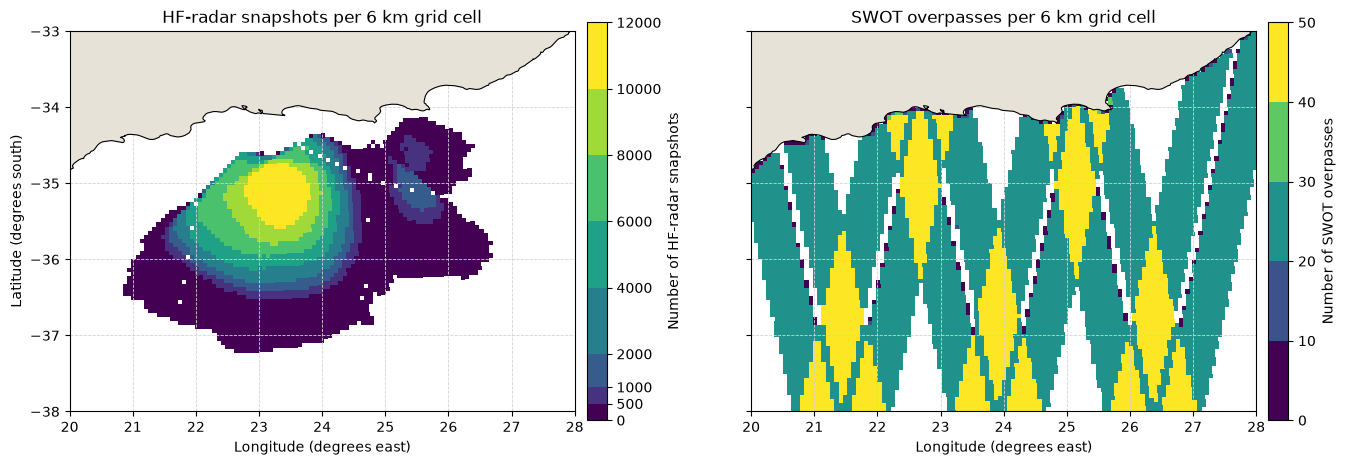

In [9]:
# Figure S1: count HF-radar snapshots and SWOT overpasses on the fixed 6 km grid.
from pathlib import Path

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import box
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
zarr_path = globals().get('zarr_path', repo_root / 'data/processed/hf_radar.zarr')
swot_out_zarr_path = globals().get(
    'swot_out_zarr_path',
    repo_root / 'data/processed/swot_filtered_velocity.zarr',
)
lon_min = globals().get('lon_min', 20.0)
lon_max = globals().get('lon_max', 28.0)
lat_min = globals().get('lat_min', -38.0)
lat_max = globals().get('lat_max', -33.0)

grid_spacing_m = 6_000
data_crs = ccrs.PlateCarree()
grid_crs = ccrs.UTM(zone=34, southern_hemisphere=True)

domain_lon = np.array([lon_min, lon_max, lon_max, lon_min])
domain_lat = np.array([lat_min, lat_min, lat_max, lat_max])
domain_xy = grid_crs.transform_points(data_crs, domain_lon, domain_lat)

x_edges = np.arange(
    np.floor(domain_xy[:, 0].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 0].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
y_edges = np.arange(
    np.floor(domain_xy[:, 1].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 1].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
n_x = len(x_edges) - 1
n_y = len(y_edges) - 1


def grid_cell_ids(longitude, latitude):
    longitude = np.asarray(longitude)
    latitude = np.asarray(latitude)
    if longitude.ndim == 1 and latitude.ndim == 1:
        longitude, latitude = np.meshgrid(longitude, latitude)
    else:
        longitude, latitude = np.broadcast_arrays(longitude, latitude)

    xy = grid_crs.transform_points(data_crs, longitude.ravel(), latitude.ravel())
    ix = np.digitize(xy[:, 0], x_edges) - 1
    iy = np.digitize(xy[:, 1], y_edges) - 1
    inside = (
        np.isfinite(xy[:, 0])
        & np.isfinite(xy[:, 1])
        & (ix >= 0)
        & (ix < n_x)
        & (iy >= 0)
        & (iy < n_y)
    )
    cell_ids = np.full(xy.shape[0], -1, dtype=int)
    cell_ids[inside] = iy[inside] * n_x + ix[inside]
    return cell_ids


hf_count_name = "snapshot_count"
swot_count_name = "overpass_count"
hf_count_archive = xr.open_zarr(zarr_path, consolidated=True)
swot_count_archive = xr.open_zarr(swot_out_zarr_path, consolidated=True)


def count_distinct_passes(u_velocity, v_velocity, cell_ids, label):
    """Count time steps containing one or more valid vectors per grid cell."""
    counts = np.zeros(n_x * n_y, dtype=np.int32)

    for time_index in range(u_velocity.sizes["time"]):
        u_slice = np.asarray(u_velocity.isel(time=time_index).values).ravel()
        v_slice = np.asarray(v_velocity.isel(time=time_index).values).ravel()
        current_cell_ids = cell_ids[time_index] if cell_ids.ndim > 1 else cell_ids
        valid_cells = current_cell_ids[
            np.isfinite(u_slice)
            & np.isfinite(v_slice)
            & (current_cell_ids >= 0)
        ]
        counts[np.unique(valid_cells)] += 1

        if (time_index + 1) % 500 == 0 or time_index + 1 == u_velocity.sizes["time"]:
            print(f"{label}: processed {time_index + 1}/{u_velocity.sizes['time']} time steps")

    return counts.reshape(n_y, n_x)


def save_fixed_grid_count(archive_path, variable_name, values, description):
    """Append a fixed-grid count variable to an existing Zarr archive."""
    count_ds = xr.Dataset(
        {
            variable_name: (("grid_y", "grid_x"), values.astype("int32")),
        },
        coords={
            "grid_y": np.arange(n_y),
            "grid_x": np.arange(n_x),
        },
    )
    count_ds[variable_name].attrs = {
        "long_name": description,
        "units": "count",
    }
    for variable in count_ds.variables:
        count_ds[variable].encoding = {}
    count_ds.to_zarr(
        archive_path,
        mode="a",
        consolidated=True,
        zarr_format=2,
    )


if hf_count_name in hf_count_archive.data_vars:
    print(f"Loading existing {hf_count_name} from {zarr_path}")
    hf_snapshot_count = hf_count_archive[hf_count_name].load().values
else:
    print(f"Calculating and adding {hf_count_name} to {zarr_path}")
    hf_cell_ids = grid_cell_ids(hf_count_archive.longitude.values, hf_count_archive.latitude.values)
    hf_snapshot_count = count_distinct_passes(
        hf_count_archive["ewct"],
        hf_count_archive["nsct"],
        hf_cell_ids,
        "HF-radar",
    )
    save_fixed_grid_count(
        zarr_path,
        hf_count_name,
        hf_snapshot_count,
        "number of HF-radar snapshots per fixed grid cell",
    )

if swot_count_name in swot_count_archive.data_vars:
    print(f"Loading existing {swot_count_name} from {swot_out_zarr_path}")
    swot_overpass_count = swot_count_archive[swot_count_name].load().values
else:
    print(f"Calculating and adding {swot_count_name} to {swot_out_zarr_path}")
    swot_cell_ids = np.stack(
        [
            grid_cell_ids(
                swot_count_archive.longitude.isel(time=time_index).compute().values,
                swot_count_archive.latitude.isel(time=time_index).compute().values,
            )
            for time_index in range(swot_count_archive.sizes["time"])
        ]
    )
    swot_overpass_count = count_distinct_passes(
        swot_count_archive["ugos_filtered"],
        swot_count_archive["vgos_filtered"],
        swot_cell_ids,
        "SWOT",
    )
    save_fixed_grid_count(
        swot_out_zarr_path,
        swot_count_name,
        swot_overpass_count,
        "number of SWOT overpasses per fixed grid cell",
    )

# Transform projected grid edges back to longitude/latitude for standard plotting axes.
grid_x, grid_y = np.meshgrid(x_edges, y_edges)
grid_lonlat = data_crs.transform_points(grid_crs, grid_x, grid_y)
grid_lon = grid_lonlat[..., 0]
grid_lat = grid_lonlat[..., 1]
land_path = repo_root / "data/raw/basemaps/ne_10m_land.zip"
land = gpd.read_file(land_path).clip(box(lon_min, lat_min, lon_max, lat_max))

figure, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
figure.subplots_adjust(left=0.08, right=0.94, bottom=0.12, top=0.90, wspace=0.12)

hf_boundaries = np.array([0, 500, 1_000, 2_000, 4_000, 6_000, 8_000, 10_000, 12_000])
hf_cmap = plt.get_cmap("viridis", len(hf_boundaries) - 1)
hf_norm = mcolors.BoundaryNorm(hf_boundaries, hf_cmap.N, clip=True)
swot_boundaries = np.arange(0, 51, 10)
swot_cmap = plt.get_cmap("viridis", len(swot_boundaries) - 1)
swot_norm = mcolors.BoundaryNorm(swot_boundaries, swot_cmap.N, clip=True)

for axis, counts, title, colourbar_label in zip(
    axes,
    (hf_snapshot_count, swot_overpass_count),
    ("HF-radar snapshots per 6 km grid cell", "SWOT overpasses per 6 km grid cell"),
    ("Number of HF-radar snapshots", "Number of SWOT overpasses"),
):
    land.plot(ax=axis, color="#e7e2d8", zorder=2)
    land.boundary.plot(ax=axis, color="black", linewidth=0.8, zorder=3)
    is_swot = title.startswith("SWOT")
    boundaries = swot_boundaries if is_swot else hf_boundaries
    cmap = swot_cmap if is_swot else hf_cmap
    norm = swot_norm if is_swot else hf_norm
    mesh = axis.pcolormesh(
        grid_lon,
        grid_lat,
        np.ma.masked_where(counts == 0, counts),
        shading="auto",
        cmap=cmap,
        norm=norm,
        zorder=1,
    )
    axis.set_xlim(lon_min, lon_max)
    axis.set_ylim(lat_min, lat_max)
    axis.set_title(title)
    axis.set_xlabel("Longitude (degrees east)")
    axis.grid(color="lightgrey", linestyle="--", linewidth=0.6)
    colourbar = figure.colorbar(
        mesh,
        ax=axis,
        shrink=0.85,
        pad=0.02,
        ticks=boundaries,
        boundaries=boundaries,
        spacing="proportional",
    )
    colourbar.set_label(colourbar_label)

axes[0].set_ylabel("Latitude (degrees south)")
plt.show()

Figure S1: Spatial distribution of the number of valid HF-radar snapshots (left) and SWOT overpasses (right) containing at least one valid velocity vector within each 6 km × 6 km grid cell over the study domain (20–28°E, 33–38°S).

In [10]:
# Summarise HF-radar quality fields where both velocity components are valid.
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

radar_path = Path('<repo>/data/processed/hf_radar.zarr')
quality_fields = ('ewct_error', 'nsct_error', 'gdopx', 'gdopy')

with xr.open_zarr(radar_path, consolidated=True, chunks=None) as radar:
    valid_velocity = np.isfinite(radar['ewct'].values) & np.isfinite(radar['nsct'].values)
    velocity_count = int(valid_velocity.sum())
    print(f'HF-radar snapshots: {radar.sizes["time"]:,}; valid velocity pixels: {velocity_count:,}')
    rows = []
    for name in quality_fields:
        field = radar[name]
        values = field.values[valid_velocity]
        finite = values[np.isfinite(values)]
        rows.append({
            'variable': name,
            'units': field.attrs.get('units', 'not specified'),
            'description': field.attrs.get('long_name', 'not specified'),
            'available': len(finite),
            'coverage (%)': 100 * len(finite) / velocity_count if velocity_count else np.nan,
            'negative': int((finite < 0).sum()),
            'zero': int((finite == 0).sum()),
            'min': np.min(finite) if finite.size else np.nan,
            'median': np.median(finite) if finite.size else np.nan,
            'p95': np.percentile(finite, 95) if finite.size else np.nan,
            'p99': np.percentile(finite, 99) if finite.size else np.nan,
            'max': np.max(finite) if finite.size else np.nan,
        })

    display(pd.DataFrame(rows).set_index('variable').round(3))

HF-radar snapshots: 18,604; valid velocity pixels: 7,793,199


,units,description,available,coverage (%),negative,zero,min,median,p95,p99,max
variable,,,,,,,,,,,
ewct_error,m s-1,Accuracy of U component of velocity,7793199,100.0,0,0,0.752,1.564,2.838,3.383,5.224
nsct_error,m s-1,Accuracy of V component of velocity,7793199,100.0,0,0,0.593,0.884,1.402,1.909,4.947
gdopx,not specified,Longitudinal dilution of precision,7793199,100.0,0,0,0.564,2.322,7.802,11.307,24.909
gdopy,not specified,Latitudinal dilution of precision,7793199,100.0,0,0,0.168,0.575,1.691,3.380,18.094


SWOT overpass: Cycle 031, Pass 542
Requested granule filename time: 2025-04-26 11:59:01 UTC
SWOT footprint median time: 2025-04-26 12:35:12 UTC
HF-radar observation time: 2025-04-26 12:30:00 UTC
SWOT-HF-radar time gap: 0 days 00:05:12.560981696
Matched zarr index: 3


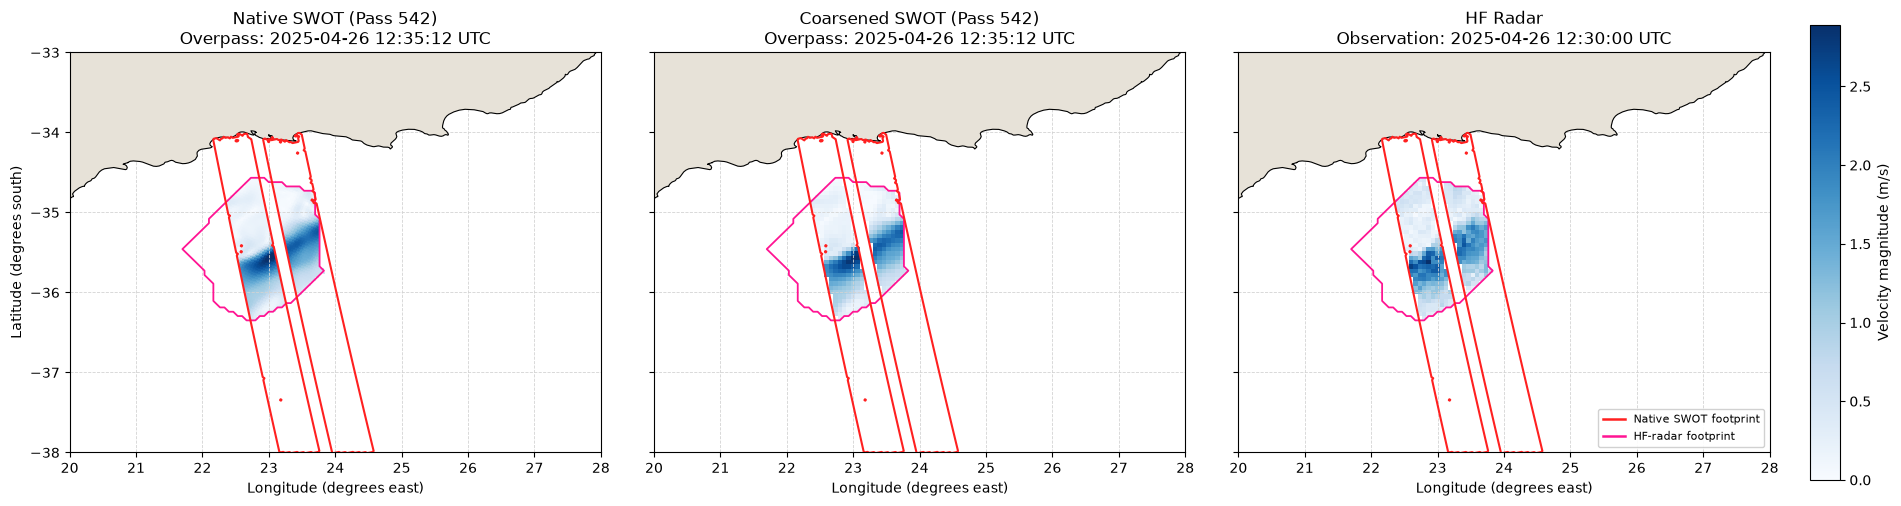

In [11]:
# Plot the requested SWOT overpass from the zarr-based matched archive.
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import RegularGridInterpolator
from shapely.geometry import box
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
swot_filtered_zarr_path = globals().get(
    'swot_out_zarr_path',
    processed_dir / 'swot_filtered_velocity.zarr',
)
PLOT_BBOX = (
    globals().get('lon_min', 20.0),
    globals().get('lon_max', 28.0),
    globals().get('lat_min', -38.0),
    globals().get('lat_max', -33.0),
)

# The requested timestamp is from the granule filename; the archive stores
# the median measurement time where SWOT overlaps the HF-radar footprint.
target_cycle = 31
target_pass = 542
target_swot_time = pd.Timestamp('2025-04-26 11:59:01')
maximum_target_time_offset = pd.Timedelta(hours=1)

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')
if not swot_filtered_zarr_path.exists():
    raise FileNotFoundError(f'SWOT filtered zarr archive not found: {swot_filtered_zarr_path}. Run Cell 3 first.')

matched_ds = xr.open_zarr(matched_zarr_path, consolidated=True)
swot_times = pd.DatetimeIndex(pd.to_datetime(matched_ds['swot_time'].values))
nearest_index = int(np.argmin(np.abs(swot_times - target_swot_time)))
nearest_time = swot_times[nearest_index]
time_offset = abs(nearest_time - target_swot_time)
if time_offset > maximum_target_time_offset:
    raise ValueError(
        f'No matched SWOT overpass is within {maximum_target_time_offset} of the requested '
        f'filename time {target_swot_time}. Nearest stored representative time is {nearest_time} '
        f'({time_offset} away).'
    )

match_index = nearest_index
matched_record = matched_ds.isel(match=match_index)
source_swot_index = int(matched_record['source_swot_index'].values)
swot_footprint_time = pd.Timestamp(matched_record['swot_time'].values)
radar_observation_time = pd.Timestamp(matched_record['radar_time'].values)

with xr.open_zarr(swot_filtered_zarr_path, consolidated=True) as swot_ds:
    u_native = np.asarray(swot_ds['ugos_filtered'].isel(time=source_swot_index).values, dtype=float)
    v_native = np.asarray(swot_ds['vgos_filtered'].isel(time=source_swot_index).values, dtype=float)
    lon_native = np.asarray(swot_ds['longitude'].isel(time=source_swot_index).values, dtype=float)
    lat_native = np.asarray(swot_ds['latitude'].isel(time=source_swot_index).values, dtype=float)

radar_lon = np.asarray(matched_ds['longitude'].values, dtype=float)
radar_lat = np.asarray(matched_ds['latitude'].values, dtype=float)
speed_coarse = np.asarray(matched_record['swot_speed_coarsened_masked'].values, dtype=float)
speed_radar = np.asarray(matched_record['radar_speed_masked'].values, dtype=float)
radar_valid = np.asarray(matched_record['radar_valid_mask'].values, dtype=bool)

swot_valid = (
    np.isfinite(u_native)
    & np.isfinite(v_native)
    & np.isfinite(lon_native)
    & np.isfinite(lat_native)
    & (lon_native >= PLOT_BBOX[0])
    & (lon_native <= PLOT_BBOX[1])
    & (lat_native >= PLOT_BBOX[2])
    & (lat_native <= PLOT_BBOX[3])
)
radar_interp = RegularGridInterpolator(
    (radar_lat, radar_lon),
    radar_valid,
    method='nearest',
    bounds_error=False,
    fill_value=False,
)
native_points = np.column_stack((lat_native.ravel(), lon_native.ravel()))
swot_on_radar_footprint = np.asarray(
    radar_interp(native_points), dtype=bool,
).reshape(lat_native.shape)
native_swot_overlap_mask = swot_valid & swot_on_radar_footprint
speed_native = np.where(native_swot_overlap_mask, np.hypot(u_native, v_native), np.nan)

valid_speeds = np.concatenate([
    values[np.isfinite(values)]
    for values in (speed_native, speed_coarse, speed_radar)
    if np.isfinite(values).any()
])
colour_limit = float(np.nanpercentile(valid_speeds, 99.5)) if valid_speeds.size else 1.0
colour_limit = max(colour_limit, 1.0)

print(f'SWOT overpass: Cycle {target_cycle:03d}, Pass {target_pass:03d}')
print(f'Requested granule filename time: {target_swot_time:%Y-%m-%d %H:%M:%S} UTC')
print(f'SWOT footprint median time: {swot_footprint_time:%Y-%m-%d %H:%M:%S} UTC')
print(f'HF-radar observation time: {radar_observation_time:%Y-%m-%d %H:%M:%S} UTC')
print(f'SWOT-HF-radar time gap: {abs(radar_observation_time - swot_footprint_time)}')
print(f'Matched zarr index: {match_index}')

land_path = repo_root / 'data/raw/basemaps/ne_10m_land.zip'
land = gpd.read_file(land_path).clip(box(PLOT_BBOX[0], PLOT_BBOX[2], PLOT_BBOX[1], PLOT_BBOX[3]))

figure, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)

panel_data = [
    (
        speed_native,
        lon_native,
        lat_native,
        f'Native SWOT (Pass {target_pass})\nOverpass: {swot_footprint_time:%Y-%m-%d %H:%M:%S} UTC',
    ),
    (
        speed_coarse,
        radar_lon,
        radar_lat,
        f'Coarsened SWOT (Pass {target_pass})\nOverpass: {swot_footprint_time:%Y-%m-%d %H:%M:%S} UTC',
    ),
    (
        speed_radar,
        radar_lon,
        radar_lat,
        f'HF Radar\nObservation: {radar_observation_time:%Y-%m-%d %H:%M:%S} UTC',
    ),
]

with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='.*input coordinates to pcolormesh.*')
    for axis, (speed, longitude, latitude, title) in zip(axes, panel_data):
        land.plot(ax=axis, color='#e7e2d8', zorder=2)
        land.boundary.plot(ax=axis, color='black', linewidth=0.8, zorder=3)
        axis.pcolormesh(
            longitude,
            latitude,
            speed,
            cmap='Blues',
            vmin=0,
            vmax=colour_limit,
            shading='nearest',
            zorder=1,
        )
        axis.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
        axis.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
        axis.set_title(title)
        axis.set_xlabel('Longitude (degrees east)')
        axis.grid(color='lightgrey', linestyle='--', linewidth=0.6)

    for axis in axes:
        axis.contour(
            lon_native,
            lat_native,
            swot_valid.astype(float),
            levels=[0.5],
            colors='#ff2020',
            linewidths=1.5,
            zorder=5,
        )
        axis.contour(
            radar_lon,
            radar_lat,
            radar_valid.astype(float),
            levels=[0.5],
            colors='deeppink',
            linewidths=1.3,
            zorder=4,
        )

axes[0].set_ylabel('Latitude (degrees south)')

colourbar_axis = figure.add_axes([0.92, 0.15, 0.015, 0.7])
figure.colorbar(
    plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=0, vmax=colour_limit),
        cmap='Blues',
    ),
    cax=colourbar_axis,
    label='Velocity magnitude (m/s)',
)

legend_handles = [
    plt.Line2D([], [], color='#ff2020', linewidth=1.8, label='Native SWOT footprint'),
    plt.Line2D([], [], color='deeppink', linewidth=1.8, label='HF-radar footprint'),
]
axes[2].legend(
    handles=legend_handles,
    loc='lower right',
    fontsize=8,
    framealpha=0.9,
)

figure.subplots_adjust(
    left=0.05,
    right=0.90,
    bottom=0.12,
    top=0.88,
    wspace=0.10,
)
plt.show()

Figure S2. Velocity-magnitude comparison for SWOT cycle 31, pass 542. The native SWOT and coarsened SWOT panels show the SWOT overpass at the median time of the valid observations crossing the HF-radar footprint (26 April 2025, 12:35:03 UTC). The HF-radar panel shows the matched observation at 12:30:00 UTC, giving an absolute time difference of 5 min 12 s. Red and pink outlines indicate the native SWOT and HF-radar footprints, respectively.

In [12]:
# Table S1: matched SWOT-HF-radar observations from the zarr-based comparison archive.
from pathlib import Path
import re

import numpy as np
import pandas as pd
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
swot_raw_dir = repo_root / 'data' / 'raw' / 'swot_l3_expert'
maximum_filename_time_offset = pd.Timedelta(hours=1)

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')

filename_pattern = re.compile(
    r'SWOT_L3_LR_SSH_Expert_(\d{3})_(\d{3})_(\d{8}T\d{6})_'
)
swot_file_metadata = {}
for swot_file in sorted(swot_raw_dir.glob('SWOT_L3_LR_SSH_Expert_*.nc')):
    match = filename_pattern.search(swot_file.name)
    if match is None:
        continue
    swot_time = pd.to_datetime(match.group(3), format='%Y%m%dT%H%M%S')
    swot_file_metadata.setdefault(
        swot_time,
        {
            'Cycle': int(match.group(1)),
            'Pass': int(match.group(2)),
        },
    )
swot_filename_times = pd.DatetimeIndex(sorted(swot_file_metadata))

with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    rows = []
    for match_index in range(matched_ds.sizes['match']):
        record = matched_ds.isel(match=match_index)
        swot_time = pd.Timestamp(record['swot_time'].values)
        radar_time = pd.Timestamp(record['radar_time'].values)
        filename_index = int(np.argmin(np.abs(swot_filename_times - swot_time)))
        filename_time = swot_filename_times[filename_index]
        if abs(filename_time - swot_time) <= maximum_filename_time_offset:
            metadata = swot_file_metadata[filename_time]
        else:
            metadata = {}
        comparison_mask = np.asarray(record['comparison_mask'].values, dtype=bool)

        rows.append(
            {
                'Match': match_index + 1,
                'Cycle': metadata.get('Cycle', pd.NA),
                'Pass': metadata.get('Pass', pd.NA),
                'SWOT time (UTC)': swot_time.strftime('%Y-%m-%d %H:%M:%S'),
                'HF-radar time (UTC)': radar_time.strftime('%Y-%m-%d %H:%M:%S'),
                'Time gap (min, sec)': float(record['time_gap_seconds'].values) / 60,
                'Paired cells': int(comparison_mask.sum()),
                'Native SWOT overlap pixels': int(record['native_swot_overlap_pixels'].values),
            }
        )

matched_observation_table = pd.DataFrame(rows)
matched_observation_table = matched_observation_table.sort_values(
    ['SWOT time (UTC)', 'Cycle', 'Pass'],
    na_position='last',
).reset_index(drop=True)
matched_observation_table['Match'] = np.arange(1, len(matched_observation_table) + 1)

mean_gap_total_seconds = int(round(matched_observation_table['Time gap (min, sec)'].mean() * 60))
mean_gap_minutes, mean_gap_seconds = divmod(mean_gap_total_seconds, 60)
print(f'Matches: {len(matched_observation_table):,}')
print(f'Mean time gap: {mean_gap_minutes}\' {mean_gap_seconds:02d}"')
print(f'Total paired cells: {matched_observation_table["Paired cells"].sum():,}')
print(
    'Total native SWOT overlap pixels: '
    f'{matched_observation_table["Native SWOT overlap pixels"].sum():,}'
)


def format_time_gap(minutes):
    total_seconds = int(round(float(minutes) * 60))
    whole_minutes, seconds = divmod(total_seconds, 60)
    return f'{whole_minutes}\' {seconds:02d}"'


styled_matched_observation_table = matched_observation_table.style.format(
    {
        'Time gap (min, sec)': format_time_gap,
    }
)
styled_matched_observation_table

Matches: 31
Mean time gap: 7' 22"
Total paired cells: 5,373
Total native SWOT overlap pixels: 51,598


,Match,Cycle,Pass,SWOT time (UTC),HF-radar time (UTC),"Time gap (min, sec)",Paired cells,Native SWOT overlap pixels
0,1,23,555,2024-11-11 01:22:32,2024-11-11 01:30:00,"7' 28""",236,2262
1,2,29,514,2025-03-14 19:04:20,2025-03-14 19:00:00,"4' 21""",2,27
2,3,29,527,2025-03-15 05:52:29,2025-03-15 06:00:00,"7' 31""",85,828
3,4,31,542,2025-04-26 12:35:12,2025-04-26 12:30:00,"5' 13""",413,3954
4,5,31,555,2025-04-26 23:23:08,2025-04-26 23:30:00,"6' 51""",162,1564
5,6,33,542,2025-06-07 06:05:21,2025-06-07 06:00:00,"5' 22""",356,3401
6,7,33,555,2025-06-07 16:53:18,2025-06-07 17:00:00,"6' 42""",136,1336
7,8,35,542,2025-07-18 23:35:33,2025-07-18 23:30:00,"5' 33""",242,2343
8,9,35,555,2025-07-19 10:23:29,2025-07-19 10:30:00,"6' 30""",307,2930
9,10,36,542,2025-08-08 20:20:36,2025-08-08 20:30:00,"9' 24""",211,2000


Table S1. Matched SWOT-HF-radar observations. SWOT time is the median time of valid SWOT data crossing the HF-radar footprint. Paired cells are valid coarsened-SWOT/HF-radar grid-cell comparisons.

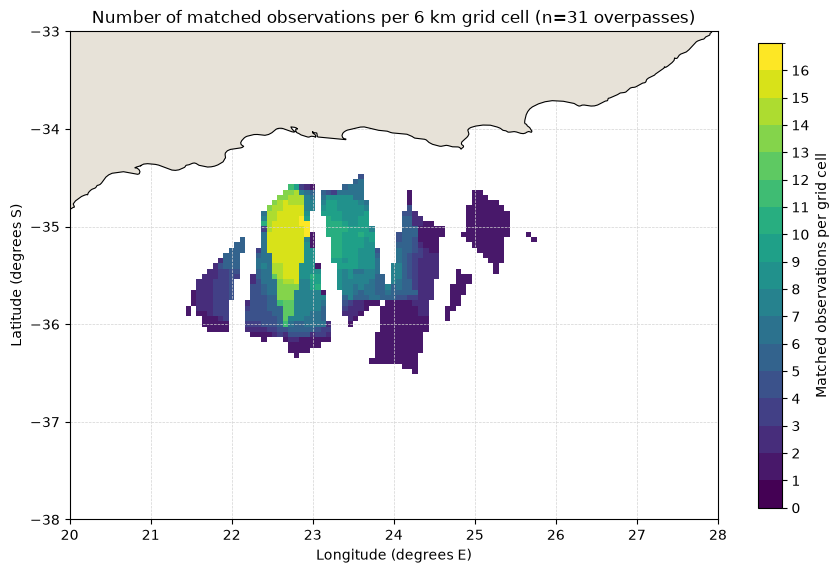

Overpasses included: 31
Grid shape: 75 lat x 150 lon (6 km resolution)
Grid cells with at least 1 matched observation: 1,008
Maximum matched observations in a single cell: 16


In [13]:
# Count matched SWOT-HF-radar observations per 6 km grid cell across all zarr-matched overpasses.
from pathlib import Path

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import box
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
PLOT_BBOX = (
    globals().get('lon_min', 20.0),
    globals().get('lon_max', 28.0),
    globals().get('lat_min', -38.0),
    globals().get('lat_max', -33.0),
)

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')


def centre_edges(coordinates):
    coordinates = np.asarray(coordinates, dtype=float)
    differences = np.diff(coordinates)
    if coordinates.size < 2 or not np.all(differences > 0):
        raise ValueError('Coordinates must be finite, unique, and increasing.')
    edges = np.empty(coordinates.size + 1, dtype=float)
    edges[1:-1] = (coordinates[:-1] + coordinates[1:]) / 2
    edges[0] = coordinates[0] - differences[0] / 2
    edges[-1] = coordinates[-1] + differences[-1] / 2
    return edges


with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    grid_latitude = np.asarray(matched_ds['latitude'].values, dtype=float)
    grid_longitude = np.asarray(matched_ds['longitude'].values, dtype=float)
    swot_speed = np.asarray(matched_ds['swot_speed_coarsened_masked'].values, dtype=float)
    radar_speed = np.asarray(matched_ds['radar_speed_masked'].values, dtype=float)
    comparison_mask = np.asarray(matched_ds['comparison_mask'].values, dtype=bool)
    number_of_overpasses = matched_ds.sizes['match']

paired_valid = comparison_mask & np.isfinite(swot_speed) & np.isfinite(radar_speed)
matched_observation_count = paired_valid.sum(axis=0).astype(int)
maximum_matched_observations = int(matched_observation_count.max())
count_plot = np.where(matched_observation_count > 0, matched_observation_count, np.nan)
count_lat_edges = centre_edges(grid_latitude)
count_lon_edges = centre_edges(grid_longitude)

count_levels = np.arange(0, maximum_matched_observations + 2)
count_cmap = plt.get_cmap('viridis', max(len(count_levels) - 1, 1))
count_norm = mcolors.BoundaryNorm(count_levels, count_cmap.N)

land_path = repo_root / 'data/raw/basemaps/ne_10m_land.zip'
land = gpd.read_file(land_path).clip(box(PLOT_BBOX[0], PLOT_BBOX[2], PLOT_BBOX[1], PLOT_BBOX[3]))

figure, axis = plt.subplots(figsize=(9, 6))
land.plot(ax=axis, color='#e7e2d8', zorder=2)
land.boundary.plot(ax=axis, color='black', linewidth=0.8, zorder=3)
mesh = axis.pcolormesh(
    count_lon_edges,
    count_lat_edges,
    count_plot,
    cmap=count_cmap,
    norm=count_norm,
    zorder=1,
)
axis.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
axis.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
axis.set_title(
    f'Number of matched observations per 6 km grid cell (n={number_of_overpasses} overpasses)'
)
axis.set_xlabel('Longitude (degrees E)')
axis.set_ylabel('Latitude (degrees S)')
axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
figure.colorbar(
    mesh,
    ax=axis,
    ticks=np.arange(0, maximum_matched_observations + 1),
    label='Matched observations per grid cell',
    shrink=0.85,
)
figure.tight_layout()
plt.show()

print(f'Overpasses included: {number_of_overpasses}')
print(f'Grid shape: {grid_latitude.size} lat x {grid_longitude.size} lon (6 km resolution)')
print(f'Grid cells with at least 1 matched observation: {(matched_observation_count > 0).sum():,}')
print(f'Maximum matched observations in a single cell: {maximum_matched_observations}')

Figure S3. Spatial distribution of matched SWOT–HF-radar observations on the 6 km HF-radar grid. Each count represents one grid-cell comparison from one of the 35 matched overpasses. A total of 1,128 grid cells contain at least one matched observation, with a maximum of 20 observations per grid cell.

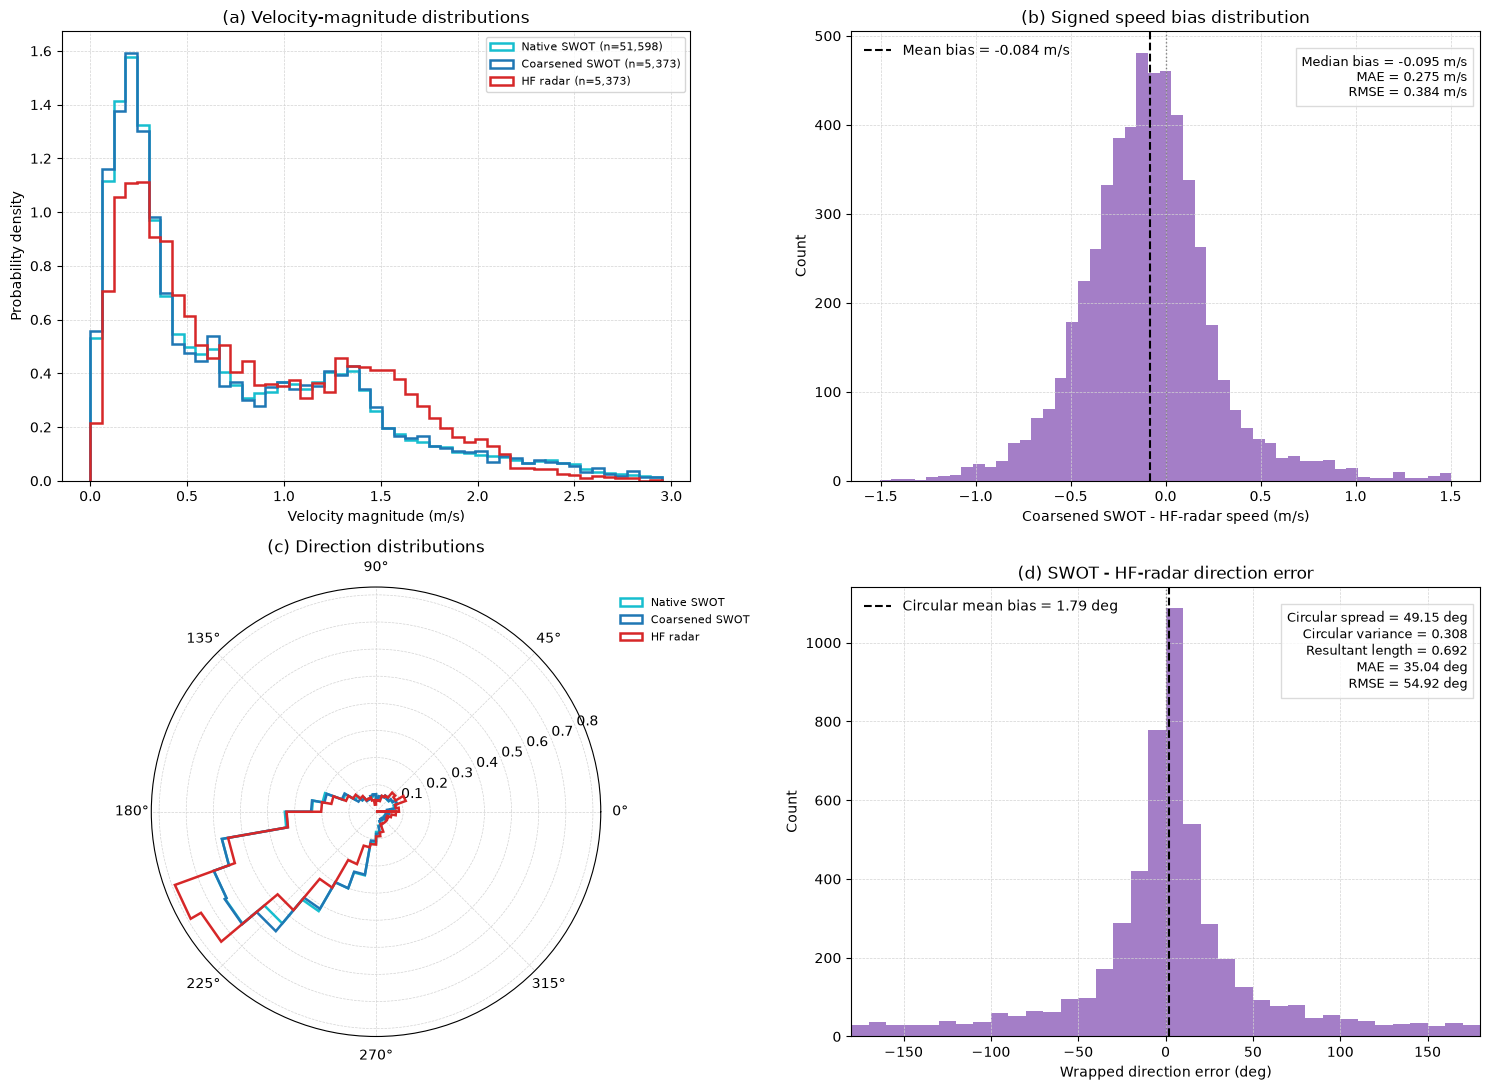

Native SWOT masked pixels: 51,598
Paired coarsened-SWOT/HF-radar speed comparisons: 5,373
Paired direction comparisons: 5,211
Mean speed bias: -0.0845 m/s
Speed RMSE: 0.3836 m/s
Circular direction mean bias: 1.79 deg
Direction RMSE: 54.92 deg


In [14]:
# Velocity and direction comparisons from the zarr-based matched archive.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import RegularGridInterpolator
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
swot_filtered_zarr_path = globals().get(
    'swot_out_zarr_path',
    processed_dir / 'swot_filtered_velocity.zarr',
)
PLOT_BBOX = (
    globals().get('lon_min', 20.0),
    globals().get('lon_max', 28.0),
    globals().get('lat_min', -38.0),
    globals().get('lat_max', -33.0),
)
MIN_DIRECTION_SPEED = 0.05

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')
if not swot_filtered_zarr_path.exists():
    raise FileNotFoundError(f'SWOT filtered zarr archive not found: {swot_filtered_zarr_path}. Run Cell 3 first.')


def direction_components(u_component, v_component):
    speed = np.hypot(u_component, v_component)
    direction = (np.degrees(np.arctan2(v_component, u_component)) + 360.0) % 360.0
    return speed, direction


def wrapped_direction_error(model_direction, reference_direction):
    return ((model_direction - reference_direction + 180.0) % 360.0) - 180.0


with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    radar_lon = np.asarray(matched_ds['longitude'].values, dtype=float)
    radar_lat = np.asarray(matched_ds['latitude'].values, dtype=float)
    source_swot_indices = np.asarray(matched_ds['source_swot_index'].values, dtype=int)
    coarse_u = np.asarray(matched_ds['ugos_coarsened_masked'].values, dtype=float)
    coarse_v = np.asarray(matched_ds['vgos_coarsened_masked'].values, dtype=float)
    radar_u = np.asarray(matched_ds['ewct_masked'].values, dtype=float)
    radar_v = np.asarray(matched_ds['nsct_masked'].values, dtype=float)
    comparison_mask = np.asarray(matched_ds['comparison_mask'].values, dtype=bool)
    radar_valid_masks = np.asarray(matched_ds['radar_valid_mask'].values, dtype=bool)

coarse_speed, coarse_direction = direction_components(coarse_u, coarse_v)
radar_speed, radar_direction = direction_components(radar_u, radar_v)
paired_valid = (
    comparison_mask
    & np.isfinite(coarse_u)
    & np.isfinite(coarse_v)
    & np.isfinite(radar_u)
    & np.isfinite(radar_v)
)

coarse_paired_values = coarse_speed[paired_valid]
radar_paired_values = radar_speed[paired_valid]
speed_diff_values = coarse_paired_values - radar_paired_values
speed_bias = float(np.mean(speed_diff_values))
speed_rmse = float(np.sqrt(np.mean(speed_diff_values ** 2)))
speed_median_bias = float(np.median(speed_diff_values))
speed_mae = float(np.mean(np.abs(speed_diff_values)))

paired_direction_valid = paired_valid & (coarse_speed >= MIN_DIRECTION_SPEED) & (radar_speed >= MIN_DIRECTION_SPEED)
coarse_direction_paired = coarse_direction[paired_direction_valid]
radar_direction_paired = radar_direction[paired_direction_valid]
direction_error_values = wrapped_direction_error(coarse_direction_paired, radar_direction_paired)
absolute_direction_error = np.abs(direction_error_values)

error_radians = np.radians(direction_error_values)
mean_sine = np.mean(np.sin(error_radians))
mean_cosine = np.mean(np.cos(error_radians))
resultant_length = float(np.hypot(mean_sine, mean_cosine))
circular_mean_bias = float(np.degrees(np.arctan2(mean_sine, mean_cosine)))
circular_spread = (
    float(np.degrees(np.sqrt(-2.0 * np.log(resultant_length))))
    if resultant_length > 0
    else np.nan
)
circular_variance = 1.0 - resultant_length
directional_mae = float(np.mean(absolute_direction_error))
directional_rmse = float(np.sqrt(np.mean(direction_error_values ** 2)))

native_speed_values = []
native_direction_values = []
with xr.open_zarr(swot_filtered_zarr_path, consolidated=True) as swot_ds:
    for match_index, source_swot_index in enumerate(source_swot_indices):
        u_native = np.asarray(swot_ds['ugos_filtered'].isel(time=source_swot_index).values, dtype=float)
        v_native = np.asarray(swot_ds['vgos_filtered'].isel(time=source_swot_index).values, dtype=float)
        lon_native = np.asarray(swot_ds['longitude'].isel(time=source_swot_index).values, dtype=float)
        lat_native = np.asarray(swot_ds['latitude'].isel(time=source_swot_index).values, dtype=float)
        swot_valid = (
            np.isfinite(u_native)
            & np.isfinite(v_native)
            & np.isfinite(lon_native)
            & np.isfinite(lat_native)
            & (lon_native >= PLOT_BBOX[0])
            & (lon_native <= PLOT_BBOX[1])
            & (lat_native >= PLOT_BBOX[2])
            & (lat_native <= PLOT_BBOX[3])
)
        radar_interp = RegularGridInterpolator(
            (radar_lat, radar_lon),
            radar_valid_masks[match_index],
            method='nearest',
            bounds_error=False,
            fill_value=False,
        )
        native_points = np.column_stack((lat_native.ravel(), lon_native.ravel()))
        native_on_radar_footprint = np.asarray(radar_interp(native_points), dtype=bool).reshape(lat_native.shape)
        native_overlap = swot_valid & native_on_radar_footprint
        native_speed, native_direction = direction_components(u_native, v_native)
        native_direction_valid = native_overlap & (native_speed >= MIN_DIRECTION_SPEED)
        native_speed_values.append(native_speed[native_overlap])
        native_direction_values.append(native_direction[native_direction_valid])

native_speed_values = np.concatenate(native_speed_values)
native_speed_values = native_speed_values[np.isfinite(native_speed_values)]
native_direction_values = np.concatenate(native_direction_values)

histogram_speed_limit = float(np.nanpercentile(
    np.concatenate((native_speed_values, coarse_paired_values, radar_paired_values)),
    99.5,
))
histogram_speed_bins = np.linspace(0, histogram_speed_limit, 50)
bias_limit = float(np.nanpercentile(np.abs(speed_diff_values), 99.5))
bias_bins = np.linspace(-bias_limit, bias_limit, 50)
direction_bin_edges = np.linspace(0.0, 360.0, 37)
direction_error_bins = np.linspace(-180.0, 180.0, 37)

figure = plt.figure(figsize=(15, 11))
speed_axis = figure.add_subplot(2, 2, 1)
bias_axis = figure.add_subplot(2, 2, 2)
polar_axis = figure.add_subplot(2, 2, 3, projection='polar')
direction_error_axis = figure.add_subplot(2, 2, 4)

speed_axis.hist(native_speed_values, bins=histogram_speed_bins, histtype='step', linewidth=1.8, density=True, label=f'Native SWOT (n={native_speed_values.size:,})', color='#17becf')
speed_axis.hist(coarse_paired_values, bins=histogram_speed_bins, histtype='step', linewidth=1.8, density=True, label=f'Coarsened SWOT (n={coarse_paired_values.size:,})', color='#1f77b4')
speed_axis.hist(radar_paired_values, bins=histogram_speed_bins, histtype='step', linewidth=1.8, density=True, label=f'HF radar (n={radar_paired_values.size:,})', color='#d62728')
speed_axis.set_xlabel('Velocity magnitude (m/s)')
speed_axis.set_ylabel('Probability density')
speed_axis.set_title('(a) Velocity-magnitude distributions')
speed_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
speed_axis.legend(fontsize=8)

bias_axis.hist(speed_diff_values, bins=bias_bins, color='#9467bd', alpha=0.85)
bias_axis.axvline(speed_bias, color='black', linestyle='--', linewidth=1.5, label=f'Mean bias = {speed_bias:.3f} m/s')
bias_axis.axvline(0, color='grey', linestyle=':', linewidth=1)
bias_axis.text(
    0.98,
    0.95,
    f'Median bias = {speed_median_bias:.3f} m/s\nMAE = {speed_mae:.3f} m/s\nRMSE = {speed_rmse:.3f} m/s',
    transform=bias_axis.transAxes,
    ha='right',
    va='top',
    fontsize=9,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgrey'),
)
bias_axis.set_xlabel('Coarsened SWOT - HF-radar speed (m/s)')
bias_axis.set_ylabel('Count')
bias_axis.set_title('(b) Signed speed bias distribution')
bias_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
bias_axis.legend(frameon=False)

for label, direction, colour in (
    ('Native SWOT', native_direction_values, '#17becf'),
    ('Coarsened SWOT', coarse_direction_paired, '#1f77b4'),
    ('HF radar', radar_direction_paired, '#d62728'),
):
    polar_axis.hist(np.radians(direction), bins=np.radians(direction_bin_edges), histtype='step', density=True, linewidth=1.8, color=colour, label=label)
polar_axis.set_theta_zero_location('E')
polar_axis.set_theta_direction(1)
polar_axis.set_title('(c) Direction distributions')
polar_axis.set_ylabel('')
polar_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
polar_axis.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False)

direction_error_axis.hist(direction_error_values, bins=direction_error_bins, color='#9467bd', alpha=0.85, edgecolor='none', linewidth=0)
direction_error_axis.axvline(circular_mean_bias, color='black', linestyle='--', linewidth=1.5, label=f'Circular mean bias = {circular_mean_bias:.2f} deg')
direction_error_axis.axvline(0, color='grey', linestyle=':', linewidth=1)
direction_error_axis.text(
    0.98,
    0.95,
    f'Circular spread = {circular_spread:.2f} deg\n'
    f'Circular variance = {circular_variance:.3f}\n'
    f'Resultant length = {resultant_length:.3f}\n'
    f'MAE = {directional_mae:.2f} deg\n'
    f'RMSE = {directional_rmse:.2f} deg',
    transform=direction_error_axis.transAxes,
    ha='right',
    va='top',
    fontsize=9,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgrey'),
)
direction_error_axis.set_xlim(-180, 180)
direction_error_axis.set_title('(d) SWOT - HF-radar direction error')
direction_error_axis.set_xlabel('Wrapped direction error (deg)')
direction_error_axis.set_ylabel('Count')
direction_error_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
direction_error_axis.legend(frameon=False)

figure.tight_layout()
plt.show()

print(f'Native SWOT masked pixels: {native_speed_values.size:,}')
print(f'Paired coarsened-SWOT/HF-radar speed comparisons: {speed_diff_values.size:,}')
print(f'Paired direction comparisons: {direction_error_values.size:,}')
print(f'Mean speed bias: {speed_bias:.4f} m/s')
print(f'Speed RMSE: {speed_rmse:.4f} m/s')
print(f'Circular direction mean bias: {circular_mean_bias:.2f} deg')
print(f'Direction RMSE: {directional_rmse:.2f} deg')

Figure 1. Velocity-magnitude and directional comparison between SWOT-derived and HF-radar surface currents. Velocity distributions for native SWOT, coarsened SWOT, and HF radar are shown alongside the signed speed difference (SWOT minus HF radar). Direction distributions and wrapped directional differences are shown for paired vectors with speeds ≥ 0.05 m s⁻¹, with the dashed line indicating the circular mean directional bias. Statistics were calculated from paired 6 km grid-cell observations across the matched SWOT overpasses. Positive speed differences indicate higher SWOT speeds. Circular spread, variance, resultant length, bias, MAE, and RMSE are reported where applicable.

In [15]:
# Bootstrap summary table for key SWOT-HF-radar validation metrics.
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
matched_zarr_path = repo_root / 'data' / 'processed' / 'swot_hfradar_zarr_matches.zarr'
BOOTSTRAP_REPLICATES = 5000
RANDOM_SEED = 42
MIN_DIRECTION_SPEED = 0.05

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')


def direction_components(u_component, v_component):
    speed = np.hypot(u_component, v_component)
    direction = (np.degrees(np.arctan2(v_component, u_component)) + 360.0) % 360.0
    return speed, direction


def wrapped_direction_error(model_direction, reference_direction):
    return ((model_direction - reference_direction + 180.0) % 360.0) - 180.0


def circular_mean_degrees(errors):
    error_radians = np.radians(errors)
    return float(np.degrees(np.arctan2(
        np.mean(np.sin(error_radians)),
        np.mean(np.cos(error_radians)),
    )))


def pooled_metric_values(records):
    speed_errors = np.concatenate([record['speed_error'] for record in records])
    direction_errors = np.concatenate([record['direction_error'] for record in records])
    return {
        'velocity_bias': float(np.mean(speed_errors)),
        'velocity_rmse': float(np.sqrt(np.mean(speed_errors ** 2))),
        'velocity_mae': float(np.mean(np.abs(speed_errors))),
        'direction_bias': circular_mean_degrees(direction_errors),
        'direction_rmse': float(np.sqrt(np.mean(direction_errors ** 2))),
        'direction_mae': float(np.mean(np.abs(direction_errors))),
    }


with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    coarse_u = np.asarray(matched_ds['ugos_coarsened_masked'].values, dtype=float)
    coarse_v = np.asarray(matched_ds['vgos_coarsened_masked'].values, dtype=float)
    radar_u = np.asarray(matched_ds['ewct_masked'].values, dtype=float)
    radar_v = np.asarray(matched_ds['nsct_masked'].values, dtype=float)
    comparison_mask = np.asarray(matched_ds['comparison_mask'].values, dtype=bool)

coarse_speed, coarse_direction = direction_components(coarse_u, coarse_v)
radar_speed, radar_direction = direction_components(radar_u, radar_v)

overpass_records = []
for match_index in range(coarse_speed.shape[0]):
    speed_valid = (
        comparison_mask[match_index]
        & np.isfinite(coarse_speed[match_index])
        & np.isfinite(radar_speed[match_index])
    )
    direction_valid = (
        speed_valid
        & (coarse_speed[match_index] >= MIN_DIRECTION_SPEED)
        & (radar_speed[match_index] >= MIN_DIRECTION_SPEED)
        & np.isfinite(coarse_direction[match_index])
        & np.isfinite(radar_direction[match_index])
    )
    if not speed_valid.any() or not direction_valid.any():
        continue

    overpass_records.append(
        {
            'speed_error': coarse_speed[match_index][speed_valid] - radar_speed[match_index][speed_valid],
            'direction_error': wrapped_direction_error(
                coarse_direction[match_index][direction_valid],
                radar_direction[match_index][direction_valid],
            ),
        }
    )

if not overpass_records:
    raise ValueError('No valid matched overpass records were available for bootstrapping.')

pooled_estimate = pooled_metric_values(overpass_records)
rng = np.random.default_rng(RANDOM_SEED)
bootstrap_indices = rng.integers(
    0,
    len(overpass_records),
    size=(BOOTSTRAP_REPLICATES, len(overpass_records)),
)
bootstrap_values = {metric: np.empty(BOOTSTRAP_REPLICATES) for metric in pooled_estimate}

for replicate_index, sampled_indices in enumerate(bootstrap_indices):
    sampled_records = [overpass_records[index] for index in sampled_indices]
    replicate_metrics = pooled_metric_values(sampled_records)
    for metric_name, value in replicate_metrics.items():
        bootstrap_values[metric_name][replicate_index] = value


def interval_text(metric_name, unit):
    lower, upper = np.percentile(bootstrap_values[metric_name], [2.5, 97.5])
    if unit == 'm/s':
        return f'{lower:.3f} to {upper:.3f}'
    return f'{lower:.1f} deg to {upper:.1f} deg'


def estimate_text(metric_name, unit):
    estimate = pooled_estimate[metric_name]
    if unit == 'm/s':
        return f'{estimate:.3f} m/s'
    return f'{estimate:.1f} deg'


summary_rows = [
    {
        'Metric': 'BIAS',
        'Velocity estimate': estimate_text('velocity_bias', 'm/s'),
        'Velocity 95% interval': interval_text('velocity_bias', 'm/s'),
        'Direction estimate': estimate_text('direction_bias', 'deg'),
        'Direction 95% interval': interval_text('direction_bias', 'deg'),
    },
    {
        'Metric': 'RMSE',
        'Velocity estimate': estimate_text('velocity_rmse', 'm/s'),
        'Velocity 95% interval': interval_text('velocity_rmse', 'm/s'),
        'Direction estimate': estimate_text('direction_rmse', 'deg'),
        'Direction 95% interval': interval_text('direction_rmse', 'deg'),
    },
    {
        'Metric': 'MAE',
        'Velocity estimate': estimate_text('velocity_mae', 'm/s'),
        'Velocity 95% interval': interval_text('velocity_mae', 'm/s'),
        'Direction estimate': estimate_text('direction_mae', 'deg'),
        'Direction 95% interval': interval_text('direction_mae', 'deg'),
    },
]

bootstrap_key_metric_table = pd.DataFrame(summary_rows)
bootstrap_key_metric_table

,Metric,Velocity estimate,Velocity 95% interval,Direction estimate,Direction 95% interval
0,BIAS,-0.084 m/s,-0.135 to -0.037,1.8 deg,-2.6 deg to 6.4 deg
1,RMSE,0.384 m/s,0.333 to 0.443,54.9 deg,49.2 deg to 60.4 deg
2,MAE,0.275 m/s,0.244 to 0.311,35.0 deg,30.3 deg to 40.0 deg


Table 1. Summary statistics for the comparison between coarsened SWOT and HF-radar currents. Estimates are calculated from paired 6 km grid-cell observations across the 36 matched SWOT overpasses. Bootstrap 95% confidence intervals were obtained using overpass-level resampling with replacement.

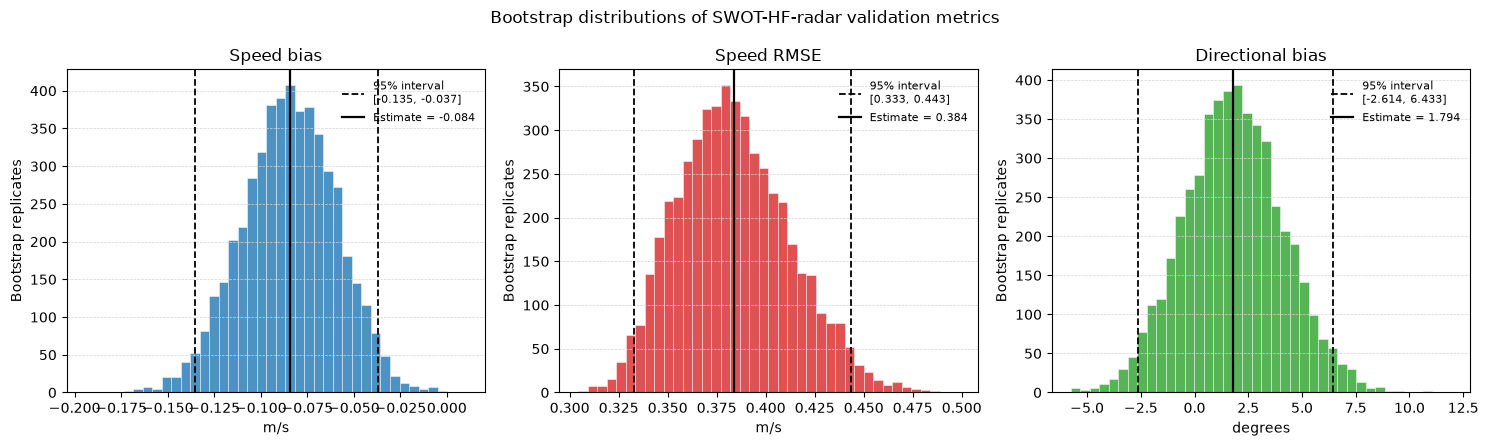

In [16]:
# Histograms of bootstrap distributions for the key validation metrics.
import matplotlib.pyplot as plt

bootstrap_plot_metrics = (
    ('velocity_bias', 'Speed bias', 'm/s', '#1f77b4'),
    ('velocity_rmse', 'Speed RMSE', 'm/s', '#d62728'),
    ('direction_bias', 'Directional bias', 'degrees', '#2ca02c'),
)

figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, (metric_name, title, unit, colour) in zip(axes, bootstrap_plot_metrics):
    values = bootstrap_values[metric_name]
    lower, upper = np.percentile(values, [2.5, 97.5])
    estimate = pooled_estimate[metric_name]

    axis.hist(values, bins=40, color=colour, alpha=0.8, edgecolor='white', linewidth=0.4)
    axis.axvline(lower, color='black', linestyle='--', linewidth=1.3, label=f'95% interval\n[{lower:.3f}, {upper:.3f}]')
    axis.axvline(upper, color='black', linestyle='--', linewidth=1.3)
    axis.axvline(estimate, color='black', linewidth=1.6, label=f'Estimate = {estimate:.3f}')
    axis.set_title(title)
    axis.set_xlabel(unit)
    axis.set_ylabel('Bootstrap replicates')
    axis.grid(axis='y', color='lightgrey', linestyle='--', linewidth=0.5)
    axis.legend(frameon=False, fontsize=8)

figure.suptitle('Bootstrap distributions of SWOT-HF-radar validation metrics')
figure.tight_layout()
plt.show()


Figure S4. Bootstrap distributions of speed bias, speed RMSE, and directional bias for coarsened SWOT currents relative to HF-radar observations. Bootstrap replicates were generated by resampling matched overpasses with replacement. Solid vertical lines indicate the pooled estimates, while dashed lines mark the 95% bootstrap confidence intervals.

In [17]:
# Calculate fixed-grid SWOT MKE/EKE and shared mean-current fields.
from pathlib import Path

import cartopy.crs as ccrs
import numpy as np
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
swot_out_zarr_path = Path(
    globals().get('swot_out_zarr_path', repo_root / 'data/processed/swot_filtered_velocity.zarr')
)
lon_min = globals().get('lon_min', 20.0)
lon_max = globals().get('lon_max', 28.0)
lat_min = globals().get('lat_min', -38.0)
lat_max = globals().get('lat_max', -33.0)
grid_spacing_m = 6_000
data_crs = ccrs.PlateCarree()
grid_crs = ccrs.UTM(zone=34, southern_hemisphere=True)

domain_xy = grid_crs.transform_points(
    data_crs,
    np.array([lon_min, lon_max, lon_max, lon_min]),
    np.array([lat_min, lat_min, lat_max, lat_max]),
)
x_edges = np.arange(
    np.floor(domain_xy[:, 0].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 0].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
y_edges = np.arange(
    np.floor(domain_xy[:, 1].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 1].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
n_x = len(x_edges) - 1
n_y = len(y_edges) - 1


def grid_cell_ids(longitude, latitude):
    """Return flattened 6 km-grid indices for a longitude/latitude field."""
    longitude = np.asarray(longitude)
    latitude = np.asarray(latitude)
    if longitude.ndim == 1 and latitude.ndim == 1:
        longitude, latitude = np.meshgrid(longitude, latitude)
    else:
        longitude, latitude = np.broadcast_arrays(longitude, latitude)
    xy = grid_crs.transform_points(data_crs, longitude.ravel(), latitude.ravel())
    ix = np.digitize(xy[:, 0], x_edges) - 1
    iy = np.digitize(xy[:, 1], y_edges) - 1
    inside = (
        np.isfinite(xy[:, 0]) & np.isfinite(xy[:, 1])
        & (ix >= 0) & (ix < n_x)
        & (iy >= 0) & (iy < n_y)
    )
    cell_ids = np.full(xy.shape[0], -1, dtype=int)
    cell_ids[inside] = iy[inside] * n_x + ix[inside]
    return cell_ids


swot_ds = xr.open_zarr(swot_out_zarr_path, consolidated=True)
fixed_grid_variables = {'mke', 'eke', 'u_mean', 'v_mean', 'grid_latitude', 'grid_longitude'}
if fixed_grid_variables.issubset(swot_ds.variables):
    print('Fixed-grid SWOT MKE/EKE and mean currents already exist; using stored fields.')
    swot_out_ds = swot_ds
elif {'mke', 'eke'}.issubset(swot_ds.data_vars):
    swot_ds.close()
    raise ValueError(
        'The SWOT archive contains MKE/EKE fields without fixed-grid coordinates. '
        'Rebuild the filtered-velocity archive before calculating fixed-grid energy.'
    )
else:
    n_passes = swot_ds.sizes['time']
    u_grid_values = np.full((n_passes, n_y * n_x), np.nan, dtype='float32')
    v_grid_values = np.full((n_passes, n_y * n_x), np.nan, dtype='float32')

    for time_index in range(n_passes):
        u_values = np.asarray(
            swot_ds['ugos_filtered'].isel(time=time_index).values, dtype=float,
        ).ravel()
        v_values = np.asarray(
            swot_ds['vgos_filtered'].isel(time=time_index).values, dtype=float,
        ).ravel()
        cell_ids = grid_cell_ids(
            swot_ds['longitude'].isel(time=time_index).values,
            swot_ds['latitude'].isel(time=time_index).values,
        )
        valid = np.isfinite(u_values) & np.isfinite(v_values) & (cell_ids >= 0)
        if valid.any():
            valid_cells = cell_ids[valid]
            counts = np.bincount(valid_cells, minlength=n_y * n_x)
            u_sums = np.bincount(valid_cells, weights=u_values[valid], minlength=n_y * n_x)
            v_sums = np.bincount(valid_cells, weights=v_values[valid], minlength=n_y * n_x)
            occupied = counts > 0
            u_grid_values[time_index, occupied] = u_sums[occupied] / counts[occupied]
            v_grid_values[time_index, occupied] = v_sums[occupied] / counts[occupied]

        if (time_index + 1) % 50 == 0 or time_index + 1 == n_passes:
            print(f'SWOT fixed-grid aggregation: {time_index + 1}/{n_passes} passes')

    grid_x = np.arange(n_x)
    grid_y = np.arange(n_y)
    grid_x_centres = 0.5 * (x_edges[:-1] + x_edges[1:])
    grid_y_centres = 0.5 * (y_edges[:-1] + y_edges[1:])
    grid_x_mesh, grid_y_mesh = np.meshgrid(grid_x_centres, grid_y_centres)
    grid_lonlat = data_crs.transform_points(grid_crs, grid_x_mesh, grid_y_mesh)
    grid_longitude = grid_lonlat[..., 0]
    grid_latitude = grid_lonlat[..., 1]
    u_grid = xr.DataArray(
        u_grid_values.reshape(n_passes, n_y, n_x),
        dims=('time', 'grid_y', 'grid_x'),
        coords={'time': swot_ds.time, 'grid_y': grid_y, 'grid_x': grid_x},
    )
    v_grid = xr.DataArray(
        v_grid_values.reshape(n_passes, n_y, n_x),
        dims=('time', 'grid_y', 'grid_x'),
        coords={'time': swot_ds.time, 'grid_y': grid_y, 'grid_x': grid_x},
    )
    u_mean_swot = u_grid.mean('time', skipna=True)
    v_mean_swot = v_grid.mean('time', skipna=True)
    mke_swot = (0.5 * (u_mean_swot**2 + v_mean_swot**2)).astype('float32')
    eke_swot = (
        0.5 * (
            ((u_grid - u_mean_swot) ** 2).mean('time', skipna=True)
            + ((v_grid - v_mean_swot) ** 2).mean('time', skipna=True)
        )
    ).astype('float32')
    n_obs_swot = (np.isfinite(u_grid) & np.isfinite(v_grid)).sum('time').astype('int32')
    swot_ke_ds = xr.Dataset(
        {
            'mke': mke_swot,
            'eke': eke_swot,
            'u_mean': u_mean_swot.astype('float32'),
            'v_mean': v_mean_swot.astype('float32'),
            'n_obs': n_obs_swot,
        },
        coords={
            'grid_longitude': (('grid_y', 'grid_x'), grid_longitude),
            'grid_latitude': (('grid_y', 'grid_x'), grid_latitude),
        },
    )
    swot_ke_ds['mke'].attrs = {
        'long_name': 'mean kinetic energy per unit mass',
        'units': 'm2 s-2',
        'description': '0.5 * (time-mean fixed-grid u^2 + time-mean fixed-grid v^2)',
    }
    swot_ke_ds['eke'].attrs = {
        'long_name': 'eddy kinetic energy per unit mass',
        'units': 'm2 s-2',
        'description': '0.5 * (mean fixed-grid u-prime^2 + mean fixed-grid v-prime^2)',
    }
    swot_ke_ds['n_obs'].attrs = {
        'long_name': 'number of SWOT overpasses contributing to each fixed grid cell',
    }
    swot_ke_ds.attrs['grid_spacing_m'] = grid_spacing_m
    swot_ke_ds.attrs['grid_projection'] = 'UTM zone 34 south'
    for variable in swot_ke_ds.variables:
        swot_ke_ds[variable].encoding = {}
    swot_ke_ds.to_zarr(
        swot_out_zarr_path,
        mode='a',
        consolidated=True,
        zarr_format=2,
    )
    swot_ds.close()
    swot_out_ds = xr.open_zarr(swot_out_zarr_path, consolidated=True)

print('Fixed-grid SWOT mean currents and kinetic energy are ready.')

SWOT fixed-grid aggregation: 50/141 passes
SWOT fixed-grid aggregation: 100/141 passes
SWOT fixed-grid aggregation: 141/141 passes
Fixed-grid SWOT mean currents and kinetic energy are ready.


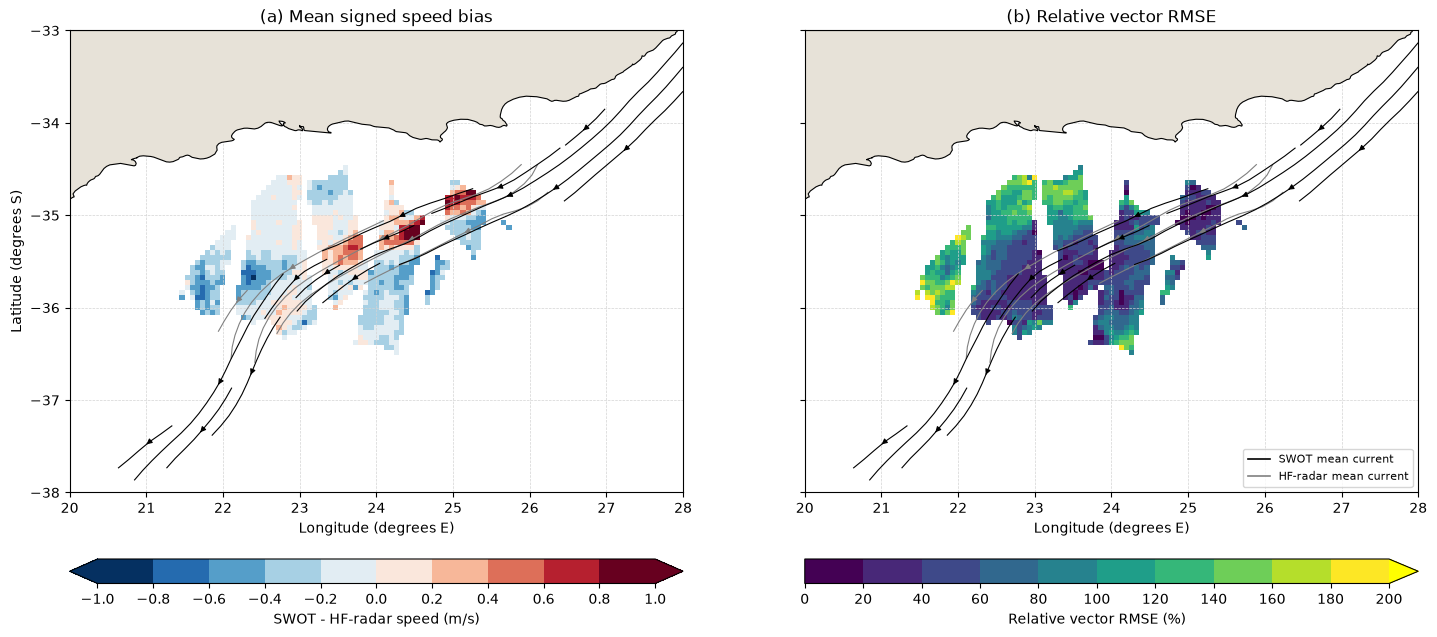

Grid cells with at least 1 paired comparison: 1,008 of 11,250
Median per-cell relative vector RMSE: 60.6%
Max per-cell relative vector RMSE: 199.1%
Mean spatial signed bias: -0.1009 m/s
Median spatial signed bias: -0.1248 m/s


In [18]:
# Spatial distribution of relative vector RMSE and signed speed bias from the zarr-based matched archive.
from pathlib import Path

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import griddata
from shapely.geometry import box
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
swot_mean_zarr_path = processed_dir / 'swot_filtered_velocity.zarr'
hf_mean_zarr_path = processed_dir / 'hf_radar.zarr'
PLOT_BBOX = (
    globals().get('lon_min', 20.0),
    globals().get('lon_max', 28.0),
    globals().get('lat_min', -38.0),
    globals().get('lat_max', -33.0),
)
STREAMLINE_SPEED_THRESHOLD = 0.75
MIN_REFERENCE_SPEED = 0.05

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')
if not swot_mean_zarr_path.exists():
    raise FileNotFoundError(f'SWOT filtered-velocity archive not found: {swot_mean_zarr_path}. Run Cell 3 first.')
if not hf_mean_zarr_path.exists():
    raise FileNotFoundError(f'HF-radar archive not found: {hf_mean_zarr_path}. Run Cell 2 first.')


def centre_edges(coordinates):
    coordinates = np.asarray(coordinates, dtype=float)
    differences = np.diff(coordinates)
    if coordinates.size < 2 or not np.all(differences > 0):
        raise ValueError('Coordinates must be finite, unique, and increasing.')
    edges = np.empty(coordinates.size + 1, dtype=float)
    edges[1:-1] = (coordinates[:-1] + coordinates[1:]) / 2
    edges[0] = coordinates[0] - differences[0] / 2
    edges[-1] = coordinates[-1] + differences[-1] / 2
    return edges


with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    error_grid_latitude = np.asarray(matched_ds['latitude'].values, dtype=float)
    error_grid_longitude = np.asarray(matched_ds['longitude'].values, dtype=float)
    coarse_u = np.asarray(matched_ds['ugos_coarsened_masked'].values, dtype=float)
    coarse_v = np.asarray(matched_ds['vgos_coarsened_masked'].values, dtype=float)
    radar_u = np.asarray(matched_ds['ewct_masked'].values, dtype=float)
    radar_v = np.asarray(matched_ds['nsct_masked'].values, dtype=float)
    comparison_mask = np.asarray(matched_ds['comparison_mask'].values, dtype=bool)

coarse_speed = np.hypot(coarse_u, coarse_v)
radar_speed = np.hypot(radar_u, radar_v)
paired_valid = (
    comparison_mask
    & np.isfinite(coarse_u)
    & np.isfinite(coarse_v)
    & np.isfinite(radar_u)
    & np.isfinite(radar_v)
)

vector_squared_error = (coarse_u - radar_u) ** 2 + (coarse_v - radar_v) ** 2
reference_speed = (coarse_speed + radar_speed) / 2
signed_speed_difference = coarse_speed - radar_speed

vector_squared_error_sum = np.nansum(np.where(paired_valid, vector_squared_error, np.nan), axis=0)
reference_speed_sum = np.nansum(np.where(paired_valid, reference_speed, np.nan), axis=0)
signed_bias_sum = np.nansum(np.where(paired_valid, signed_speed_difference, np.nan), axis=0)
error_count = paired_valid.sum(axis=0).astype(int)

with np.errstate(invalid='ignore', divide='ignore'):
    vector_rmse_grid = np.sqrt(vector_squared_error_sum / error_count)
    mean_reference_speed_grid = reference_speed_sum / error_count
    signed_bias_grid = signed_bias_sum / error_count
    relative_vector_rmse_grid = 100 * vector_rmse_grid / mean_reference_speed_grid

vector_rmse_grid = np.where(error_count > 0, vector_rmse_grid, np.nan)
mean_reference_speed_grid = np.where(error_count > 0, mean_reference_speed_grid, np.nan)
signed_bias_grid = np.where(error_count > 0, signed_bias_grid, np.nan)
relative_vector_rmse_grid = np.where(
    (error_count > 0) & (mean_reference_speed_grid >= MIN_REFERENCE_SPEED),
    relative_vector_rmse_grid,
    np.nan,
)

# Reuse the fixed-grid, time-mean SWOT currents used in the MKE/EKE figure.
with xr.open_zarr(swot_mean_zarr_path, consolidated=True) as swot_mean_ds:
    swot_mean_u = np.asarray(swot_mean_ds['u_mean'].values, dtype=float)
    swot_mean_v = np.asarray(swot_mean_ds['v_mean'].values, dtype=float)
    swot_mean_longitude = np.asarray(swot_mean_ds['grid_longitude'].values, dtype=float)
    swot_mean_latitude = np.asarray(swot_mean_ds['grid_latitude'].values, dtype=float)

with xr.open_zarr(hf_mean_zarr_path, consolidated=True, chunks=None) as hf_mean_ds:
    hf_mean_longitude, hf_mean_latitude = np.meshgrid(
        np.asarray(hf_mean_ds['longitude'].values, dtype=float),
        np.asarray(hf_mean_ds['latitude'].values, dtype=float),
    )
    if {'u_mean', 'v_mean'}.issubset(hf_mean_ds.data_vars):
        hf_mean_u = np.asarray(hf_mean_ds['u_mean'].values, dtype=float)
        hf_mean_v = np.asarray(hf_mean_ds['v_mean'].values, dtype=float)
    else:
        hf_u_sum = np.zeros(hf_mean_longitude.shape, dtype=float)
        hf_v_sum = np.zeros(hf_mean_longitude.shape, dtype=float)
        hf_count = np.zeros(hf_mean_longitude.shape, dtype=np.int64)
        for start in range(0, hf_mean_ds.sizes['time'], 128):
            time_slice = slice(start, start + 128)
            u_chunk = hf_mean_ds['ewct'].isel(time=time_slice).values
            v_chunk = hf_mean_ds['nsct'].isel(time=time_slice).values
            valid_chunk = np.isfinite(u_chunk) & np.isfinite(v_chunk)
            hf_u_sum += np.where(valid_chunk, u_chunk, 0).sum(axis=0)
            hf_v_sum += np.where(valid_chunk, v_chunk, 0).sum(axis=0)
            hf_count += valid_chunk.sum(axis=0)
        hf_mean_u = np.divide(hf_u_sum, hf_count, out=np.full_like(hf_u_sum, np.nan), where=hf_count > 0)
        hf_mean_v = np.divide(hf_v_sum, hf_count, out=np.full_like(hf_v_sum, np.nan), where=hf_count > 0)


def regularise_mean_currents(longitude, latitude, u_velocity, v_velocity):
    """Interpolate mean vectors to the shared 80 x 60 plotting grid and apply the speed cutoff."""
    valid = (
        np.isfinite(longitude)
        & np.isfinite(latitude)
        & np.isfinite(u_velocity)
        & np.isfinite(v_velocity)
    )
    streamline_longitude = np.linspace(PLOT_BBOX[0], PLOT_BBOX[1], 80)
    streamline_latitude = np.linspace(PLOT_BBOX[2], PLOT_BBOX[3], 60)
    streamline_lon2d, streamline_lat2d = np.meshgrid(streamline_longitude, streamline_latitude)
    points = np.column_stack((longitude[valid], latitude[valid]))
    streamline_u = griddata(
        points, u_velocity[valid], (streamline_lon2d, streamline_lat2d), method='linear',
    )
    streamline_v = griddata(
        points, v_velocity[valid], (streamline_lon2d, streamline_lat2d), method='linear',
    )
    streamline_speed = np.hypot(streamline_u, streamline_v)
    streamline_u[streamline_speed <= STREAMLINE_SPEED_THRESHOLD] = np.nan
    streamline_v[streamline_speed <= STREAMLINE_SPEED_THRESHOLD] = np.nan
    return streamline_longitude, streamline_latitude, streamline_u, streamline_v


streamline_longitude, streamline_latitude, stream_u, stream_v = regularise_mean_currents(
    swot_mean_longitude, swot_mean_latitude, swot_mean_u, swot_mean_v,
)
hf_streamline_longitude, hf_streamline_latitude, hf_stream_u, hf_stream_v = regularise_mean_currents(
    hf_mean_longitude, hf_mean_latitude, hf_mean_u, hf_mean_v,
)

error_lat_edges = centre_edges(error_grid_latitude)
error_lon_edges = centre_edges(error_grid_longitude)
land_path = repo_root / 'data/raw/basemaps/ne_10m_land.zip'
land = gpd.read_file(land_path).clip(box(PLOT_BBOX[0], PLOT_BBOX[2], PLOT_BBOX[1], PLOT_BBOX[3]))

rmse_levels = np.arange(0, 220, 20)
rmse_cmap = plt.get_cmap('viridis', len(rmse_levels) - 1).copy()
rmse_cmap.set_over('yellow')
rmse_norm = mcolors.BoundaryNorm(rmse_levels, rmse_cmap.N)
signed_bias_step = 0.2
signed_bias_limit = max(float(np.nanpercentile(np.abs(signed_bias_grid), 99)), signed_bias_step)
signed_bias_limit = signed_bias_step * np.ceil(signed_bias_limit / signed_bias_step)
signed_bias_boundaries = np.arange(
    -signed_bias_limit,
    signed_bias_limit + signed_bias_step / 2,
    signed_bias_step,
)
signed_bias_cmap = plt.get_cmap('RdBu_r', len(signed_bias_boundaries) - 1)
signed_bias_norm = mcolors.BoundaryNorm(signed_bias_boundaries, signed_bias_cmap.N)

streamline_handles = [
    plt.Line2D([], [], color='black', linewidth=1.2, label='SWOT mean current'),
    plt.Line2D([], [], color='grey', linewidth=1.2, label='HF-radar mean current'),
]

figure, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

land.plot(ax=axes[0], color='#e7e2d8', zorder=2)
land.boundary.plot(ax=axes[0], color='black', linewidth=0.8, zorder=3)
bias_mesh = axes[0].pcolormesh(
    error_lon_edges,
    error_lat_edges,
    signed_bias_grid,
    cmap=signed_bias_cmap,
    norm=signed_bias_norm,
    zorder=1,
)
axes[0].streamplot(
    streamline_longitude,
    streamline_latitude,
    np.ma.masked_invalid(stream_u),
    np.ma.masked_invalid(stream_v),
    color='black',
    linewidth=0.8,
    density=1.3,
    arrowsize=0.8,
    zorder=6,
)
axes[0].streamplot(
    hf_streamline_longitude,
    hf_streamline_latitude,
    np.ma.masked_invalid(hf_stream_u),
    np.ma.masked_invalid(hf_stream_v),
    color='grey',
    linewidth=0.8,
    density=1.3,
    arrowsize=0.8,
    zorder=5,
)
axes[0].set_title('(a) Mean signed speed bias')

land.plot(ax=axes[1], color='#e7e2d8', zorder=2)
land.boundary.plot(ax=axes[1], color='black', linewidth=0.8, zorder=3)
rmse_mesh = axes[1].pcolormesh(
    error_lon_edges,
    error_lat_edges,
    relative_vector_rmse_grid,
    cmap=rmse_cmap,
    norm=rmse_norm,
    zorder=1,
)
axes[1].streamplot(
    streamline_longitude,
    streamline_latitude,
    np.ma.masked_invalid(stream_u),
    np.ma.masked_invalid(stream_v),
    color='black',
    linewidth=0.8,
    density=1.3,
    arrowsize=0.8,
    zorder=6,
)
axes[1].streamplot(
    hf_streamline_longitude,
    hf_streamline_latitude,
    np.ma.masked_invalid(hf_stream_u),
    np.ma.masked_invalid(hf_stream_v),
    color='grey',
    linewidth=0.8,
    density=1.3,
    arrowsize=0.8,
    zorder=5,
)
axes[1].set_title('(b) Relative vector RMSE')
axes[1].legend(handles=streamline_handles, loc='lower right', fontsize=8, framealpha=0.8)

for axis in axes:
    axis.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
    axis.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
    axis.set_xlabel('Longitude (degrees E)')
    axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
axes[0].set_ylabel('Latitude (degrees S)')

figure.subplots_adjust(left=0.06, right=0.98, bottom=0.24, top=0.90, wspace=0.14)
left_position = axes[0].get_position()
right_position = axes[1].get_position()
bias_colourbar_axis = figure.add_axes([
    left_position.x0,
    0.11,
    left_position.width,
    0.035,
])
rmse_colourbar_axis = figure.add_axes([
    right_position.x0,
    0.11,
    right_position.width,
    0.035,
])
figure.colorbar(
    bias_mesh,
    cax=bias_colourbar_axis,
    orientation='horizontal',
    ticks=signed_bias_boundaries,
    label='SWOT - HF-radar speed (m/s)',
    extend='both',
)
figure.colorbar(
    rmse_mesh,
    cax=rmse_colourbar_axis,
    orientation='horizontal',
    ticks=rmse_levels,
    label='Relative vector RMSE (%)',
    extend='max',
)
plt.show()

print(f'Grid cells with at least 1 paired comparison: {(error_count > 0).sum():,} of {error_count.size:,}')
print(f'Median per-cell relative vector RMSE: {np.nanmedian(relative_vector_rmse_grid):.1f}%')
print(f'Max per-cell relative vector RMSE: {np.nanmax(relative_vector_rmse_grid):.1f}%')
print(f'Mean spatial signed bias: {np.nanmean(signed_bias_grid):+.4f} m/s')
print(f'Median spatial signed bias: {np.nanmedian(signed_bias_grid):+.4f} m/s')

Figure 2. Spatial distribution of signed speed bias and relative vector RMSE between coarsened SWOT and HF-radar currents. The left panel shows the mean signed speed difference, calculated as SWOT minus HF radar. The right panel shows relative vector RMSE calculated from paired eastward and northward velocity-component differences and normalised by the mean paired current speed in each grid cell. Both metrics were calculated on the common 6 km grid using all valid paired observations. Grey streamlines show the mean SWOT current field where mean speed is ⩾0.75 m/s.

In [19]:
# Match Copernicus surface currents to the accepted SWOT/HF-radar comparisons.
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
matched_path = repo_root / 'data/processed/swot_hfradar_zarr_matches.zarr'
copernicus_dir = repo_root / 'data/raw/copernicusmarine'

sources = {
    'ekman': ('cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i', 'ue', 've', '30min'),
    'tide': ('cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i', 'utide', 'vtide', '30min'),
    'stokes': ('cmems_mod_glo_wav_anfc_0.083deg_PT3H-i', 'VSDX', 'VSDY', '90min'),
}

with xr.open_zarr(matched_path, consolidated=True, chunks=None) as matched:
    matched_attrs = dict(matched.attrs)
    radar_times = xr.DataArray(
        matched.radar_time.values, dims='match', coords={'match': matched.match.values},
    )
    radar_latitude = matched.latitude.values
    radar_longitude = matched.longitude.values
    comparison_mask = matched.comparison_mask.values

matched_currents = xr.Dataset()
for component, (folder, east_name, north_name, tolerance) in sources.items():
    paths = list((copernicus_dir / folder).glob('*.nc'))
    if len(paths) != 1:
        raise ValueError(f'Expected one NetCDF file in {folder}, found {len(paths)}')
    with xr.open_dataset(paths[0]) as current_ds:
        surface = current_ds[[east_name, north_name]]
        if 'depth' in surface.dims:
            surface = surface.sel(depth=0)
        selected = surface.sel(
            time=radar_times, method='nearest', tolerance=pd.Timedelta(tolerance),
        )
        source_times = selected.time.values
        gridded = selected.interp(
            latitude=radar_latitude, longitude=radar_longitude,
        )
        east = gridded[east_name].values
        north = gridded[north_name].values

    valid = (
        comparison_mask & np.isfinite(east) & np.isfinite(north)
        & (np.abs(east) < 10) & (np.abs(north) < 10)
    )
    for direction, values in (('u', east), ('v', north)):
        matched_currents[f'{component}_{direction}_masked'] = (
            ('match', 'latitude', 'longitude'),
            np.where(valid, values, np.nan).astype(np.float32),
            {'units': 'm s-1', 'source_variable': east_name if direction == 'u' else north_name,
             'source_file': paths[0].name},
        )
    matched_currents[f'{component}_time'] = (('match',), source_times)
    matched_currents[f'{component}_time_gap_seconds'] = (
        ('match',),
        (np.abs(source_times - radar_times.values) / np.timedelta64(1, 's')).astype(np.float32),
    )
    print(f'{component}: {valid.sum()} valid comparison cells across {len(source_times)} matches')

matched_currents.attrs.update(matched_attrs)
matched_currents.to_zarr(matched_path, mode='a', consolidated=True, zarr_format=3)
print(f'Added Copernicus surface currents to {matched_path}')

ekman: 5373 valid comparison cells across 31 matches
tide: 5373 valid comparison cells across 31 matches
stokes: 5373 valid comparison cells across 31 matches
Added Copernicus surface currents to <repo>/data/processed/swot_hfradar_zarr_matches.zarr


<env>/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


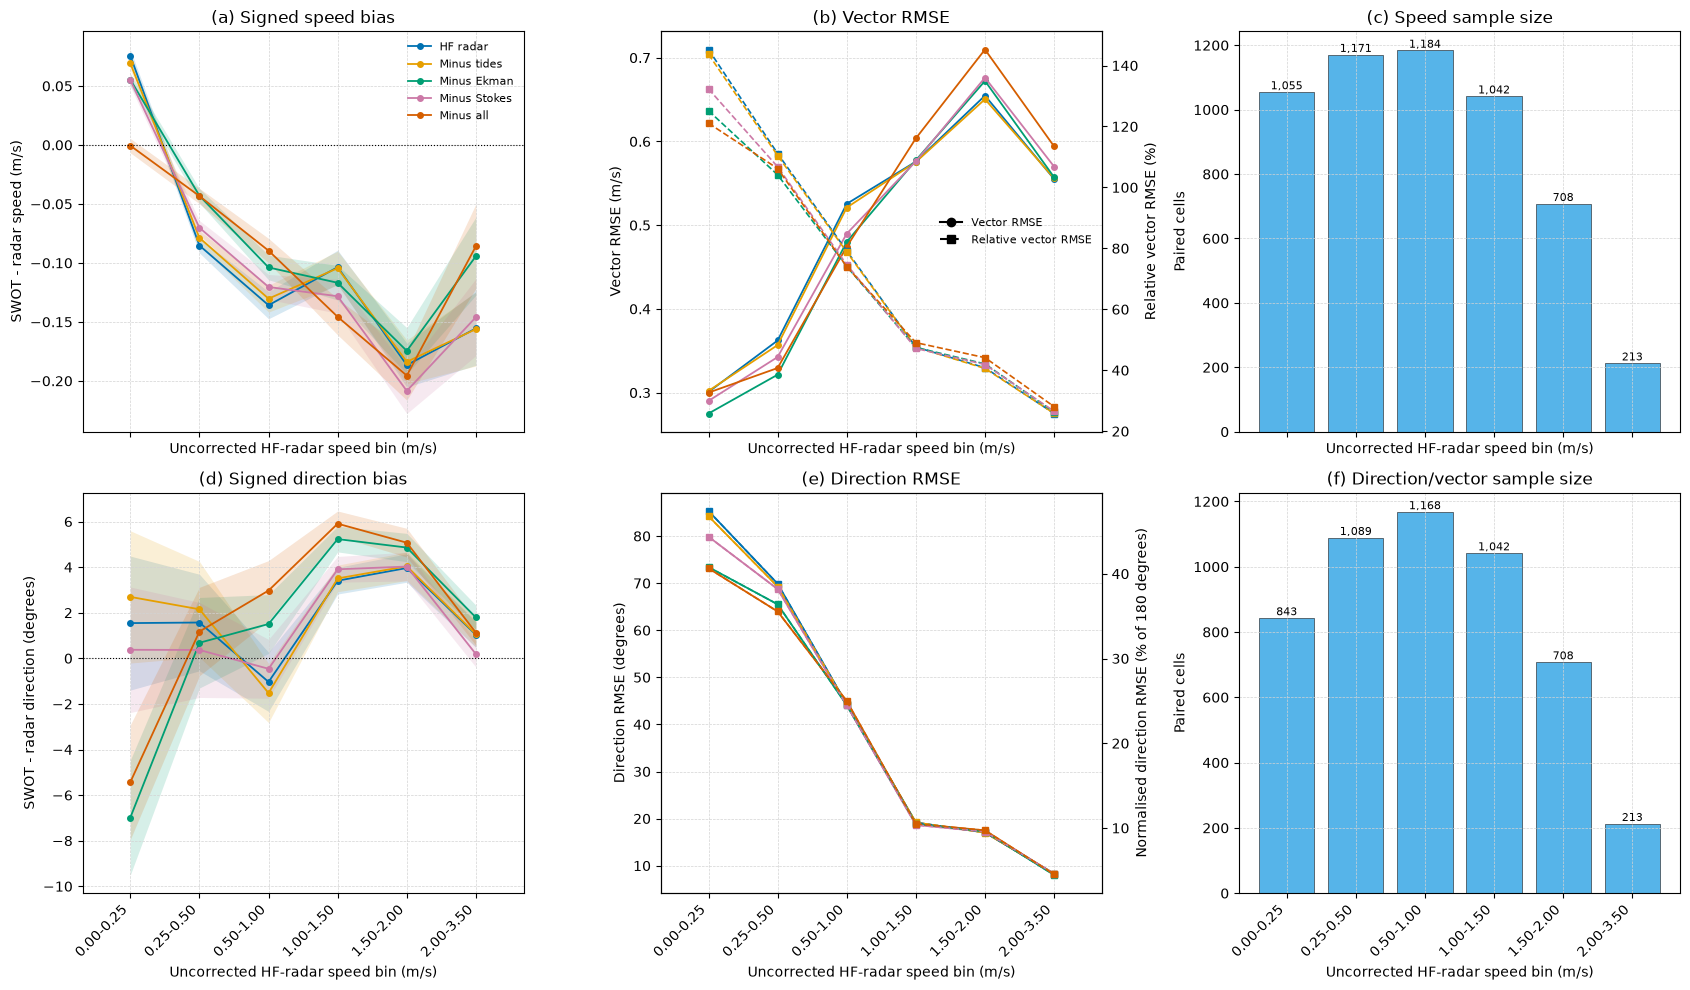

Speed pairs in bins (identical for all variants): 5,373
Direction/vector pairs in bins (identical for all variants): 5,063
Minus tides: vector RMSE change (m/s) = [0.001, -0.005, -0.004, -0.0, -0.004, 0.001], direction RMSE change (deg) = [-1.1, -0.6, 0.0, 0.0, -0.0, 0.0]
Minus Ekman: vector RMSE change (m/s) = [-0.026, -0.041, -0.045, 0.002, 0.018, 0.002], direction RMSE change (deg) = [-11.9, -4.4, -0.2, -0.2, 0.2, -0.2]
Minus Stokes: vector RMSE change (m/s) = [-0.011, -0.02, -0.036, 0.0, 0.021, 0.015], direction RMSE change (deg) = [-5.5, -1.1, -0.2, -0.5, 0.2, 0.0]
Minus all: vector RMSE change (m/s) = [-0.001, -0.033, -0.051, 0.028, 0.055, 0.039], direction RMSE change (deg) = [-12.2, -5.9, 0.7, -0.3, 0.4, -0.1]


In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
matched_path = repo_root / 'data/processed/swot_hfradar_zarr_matches.zarr'
minimum_vector_speed = 0.05

with xr.open_zarr(matched_path, consolidated=True, chunks=None) as matched_ds:
    swot_u = matched_ds.ugos_coarsened_masked.values.astype(float)
    swot_v = matched_ds.vgos_coarsened_masked.values.astype(float)
    radar_u = matched_ds.ewct_masked.values.astype(float)
    radar_v = matched_ds.nsct_masked.values.astype(float)
    paired_mask = matched_ds.comparison_mask.values.copy()
    corrections = {
        component: (
            matched_ds[f'{component}_u_masked'].values.astype(float),
            matched_ds[f'{component}_v_masked'].values.astype(float),
        )
        for component in ('tide', 'ekman', 'stokes')
    }

variants = {
    'HF radar': (radar_u, radar_v),
    'Minus tides': (radar_u - corrections['tide'][0], radar_v - corrections['tide'][1]),
    'Minus Ekman': (radar_u - corrections['ekman'][0], radar_v - corrections['ekman'][1]),
    'Minus Stokes': (radar_u - corrections['stokes'][0], radar_v - corrections['stokes'][1]),
    'Minus all': (
        radar_u - sum(values[0] for values in corrections.values()),
        radar_v - sum(values[1] for values in corrections.values()),
    ),
}
variant_colours = {
    'HF radar': '#0072B2',
    'Minus tides': '#E69F00',
    'Minus Ekman': '#009E73',
    'Minus Stokes': '#CC79A7',
    'Minus all': '#D55E00',
}

paired_mask &= np.isfinite(swot_u) & np.isfinite(swot_v)
for variant_u, variant_v in variants.values():
    paired_mask &= np.isfinite(variant_u) & np.isfinite(variant_v)
if not paired_mask.any():
    raise ValueError('No common paired SWOT/HF-radar velocities remain.')

swot_speed = np.hypot(swot_u, swot_v)
radar_speed = np.hypot(radar_u, radar_v)
swot_direction = np.degrees(np.arctan2(swot_v, swot_u))
vector_mask = paired_mask & (swot_speed >= minimum_vector_speed)
for variant_u, variant_v in variants.values():
    vector_mask &= np.hypot(variant_u, variant_v) >= minimum_vector_speed
if not vector_mask.any():
    raise ValueError('No common paired vectors meet the direction speed threshold.')

bin_edges = np.array([0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.5])
bin_labels = ['0.00-0.25', '0.25-0.50', '0.50-1.00', '1.00-1.50', '1.50-2.00', '2.00-3.50']
bin_positions = np.arange(len(bin_labels))
speed_counts = np.zeros(len(bin_labels), dtype=int)
vector_counts = np.zeros(len(bin_labels), dtype=int)
metrics = {
    label: {name: np.full(len(bin_labels), np.nan) for name in (
        'speed_bias', 'speed_sem', 'vector_rmse', 'relative_vector_rmse',
        'direction_bias', 'direction_sem', 'direction_rmse', 'direction_relative_rmse',
    )}
    for label in variants
}

for bin_index in range(len(bin_labels)):
    in_bin = (radar_speed >= bin_edges[bin_index]) & (
        (radar_speed <= bin_edges[bin_index + 1]) if bin_index == len(bin_labels) - 1
        else (radar_speed < bin_edges[bin_index + 1])
    )
    speed_valid = paired_mask & in_bin
    vector_valid = vector_mask & in_bin
    speed_counts[bin_index] = int(speed_valid.sum())
    vector_counts[bin_index] = int(vector_valid.sum())

    for label, (variant_u, variant_v) in variants.items():
        variant_speed = np.hypot(variant_u, variant_v)
        values = metrics[label]
        if speed_counts[bin_index]:
            speed_error = swot_speed[speed_valid] - variant_speed[speed_valid]
            values['speed_bias'][bin_index] = np.mean(speed_error)
            if speed_counts[bin_index] > 1:
                values['speed_sem'][bin_index] = np.std(speed_error, ddof=1) / np.sqrt(speed_counts[bin_index])
        if not vector_counts[bin_index]:
            continue
        squared_error = (swot_u[vector_valid] - variant_u[vector_valid]) ** 2 + (
            swot_v[vector_valid] - variant_v[vector_valid]
        ) ** 2
        values['vector_rmse'][bin_index] = np.sqrt(np.mean(squared_error))
        reference_speed = (swot_speed[vector_valid] + variant_speed[vector_valid]) / 2
        values['relative_vector_rmse'][bin_index] = (
            100 * values['vector_rmse'][bin_index] / np.mean(reference_speed)
        )
        variant_direction = np.degrees(np.arctan2(variant_v[vector_valid], variant_u[vector_valid]))
        direction_error = ((swot_direction[vector_valid] - variant_direction + 180) % 360) - 180
        values['direction_bias'][bin_index] = np.mean(direction_error)
        values['direction_rmse'][bin_index] = np.sqrt(np.mean(direction_error ** 2))
        values['direction_relative_rmse'][bin_index] = 100 * values['direction_rmse'][bin_index] / 180
        if vector_counts[bin_index] > 1:
            values['direction_sem'][bin_index] = np.std(direction_error, ddof=1) / np.sqrt(vector_counts[bin_index])

figure, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True)
speed_bias_axis, vector_error_axis, speed_count_axis = axes[0]
direction_bias_axis, direction_error_axis, vector_count_axis = axes[1]
relative_vector_axis = vector_error_axis.twinx()
direction_relative_axis = direction_error_axis.twinx()

for label, values in metrics.items():
    colour = variant_colours[label]
    speed_bias_axis.plot(bin_positions, values['speed_bias'], 'o-',
                         color=colour, linewidth=1.3, markersize=4, label=label)
    speed_bias_axis.fill_between(bin_positions, values['speed_bias'] - values['speed_sem'],
                                 values['speed_bias'] + values['speed_sem'],
                                 color=colour, alpha=0.16, linewidth=0)
    vector_error_axis.plot(bin_positions, values['vector_rmse'], 'o-', color=colour, linewidth=1.3, markersize=4)
    relative_vector_axis.plot(bin_positions, values['relative_vector_rmse'], 's--', color=colour,
                              linewidth=1.2, markersize=4)
    direction_bias_axis.plot(bin_positions, values['direction_bias'], 'o-',
                             color=colour, linewidth=1.3, markersize=4)
    direction_bias_axis.fill_between(bin_positions, values['direction_bias'] - values['direction_sem'],
                                     values['direction_bias'] + values['direction_sem'],
                                     color=colour, alpha=0.16, linewidth=0)
    direction_error_axis.plot(bin_positions, values['direction_rmse'], 'o-', color=colour, linewidth=1.3, markersize=4)
    direction_relative_axis.plot(bin_positions, values['direction_relative_rmse'], 's--',
                                 color=colour, linewidth=1.2, markersize=4)

speed_bias_axis.axhline(0, color='black', linestyle=':', linewidth=0.8)
direction_bias_axis.axhline(0, color='black', linestyle=':', linewidth=0.8)
speed_bias_axis.set_title('(a) Signed speed bias')
speed_bias_axis.set_ylabel('SWOT - radar speed (m/s)')
speed_bias_axis.legend(fontsize=8, loc='best', frameon=False)
vector_error_axis.set_title('(b) Vector RMSE')
vector_error_axis.set_ylabel('Vector RMSE (m/s)')
relative_vector_axis.set_ylabel('Relative vector RMSE (%)')
vector_error_axis.legend(handles=[
    plt.Line2D([], [], color='black', marker='o', label='Vector RMSE'),
    plt.Line2D([], [], color='black', marker='s', linestyle='--', label='Relative vector RMSE'),
], loc='center right', fontsize=8, frameon=False)
speed_count_axis.set_title('(c) Speed sample size')
speed_count_axis.set_ylabel('Paired cells')
direction_bias_axis.set_title('(d) Signed direction bias')
direction_bias_axis.set_ylabel('SWOT - radar direction (degrees)')
direction_error_axis.set_title('(e) Direction RMSE')
direction_error_axis.set_ylabel('Direction RMSE (degrees)')
direction_relative_axis.set_ylabel('Normalised direction RMSE (% of 180 degrees)')
vector_count_axis.set_title('(f) Direction/vector sample size')
vector_count_axis.set_ylabel('Paired cells')

for axis, counts in ((speed_count_axis, speed_counts), (vector_count_axis, vector_counts)):
    axis.bar(bin_positions, counts, width=0.8, color='#56B4E9', edgecolor='#343a40', linewidth=0.5)
    for position, count in zip(bin_positions, counts):
        if count:
            axis.text(position, count, f'{count:,}', ha='center', va='bottom', fontsize=8)
for axis in axes.ravel():
    axis.set_xticks(bin_positions)
    axis.set_xticklabels(bin_labels, rotation=45, ha='right')
    axis.set_xlabel('Uncorrected HF-radar speed bin (m/s)')
    axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)

figure.tight_layout()
plt.show()
print(f'Speed pairs in bins (identical for all variants): {speed_counts.sum():,}')
print(f'Direction/vector pairs in bins (identical for all variants): {vector_counts.sum():,}')
for label, values in metrics.items():
    if label == 'HF radar':
        continue
    vector_change = values['vector_rmse'] - metrics['HF radar']['vector_rmse']
    direction_change = values['direction_rmse'] - metrics['HF radar']['direction_rmse']
    print(f'{label}: vector RMSE change (m/s) = {np.round(vector_change, 3).tolist()}, '
          f'direction RMSE change (deg) = {np.round(direction_change, 1).tolist()}')

Figure 3. Speed dependence of agreement between SWOT and HF radar, and the effect of subtracting Copernicus tide, Ekman, and Stokes currents from the radar velocities. Panels show (a) speed bias (SWOT minus radar), (b) vector RMSE and relative vector RMSE, (c) speed-pair counts, (d) direction bias, (e) direction RMSE and normalised direction RMSE, and (f) direction/vector-pair counts. Speed bins are defined using uncorrected HF-radar speed. Raw and corrected radar variants are evaluated on the same observations within each bin; shading indicates the standard error of the mean for bias estimates. Direction statistics use paired vectors with speeds of at least 0.05 m s⁻¹ in SWOT and all radar variants. Relative vector RMSE is normalised by mean paired speed; normalised direction RMSE is expressed relative to 180°.

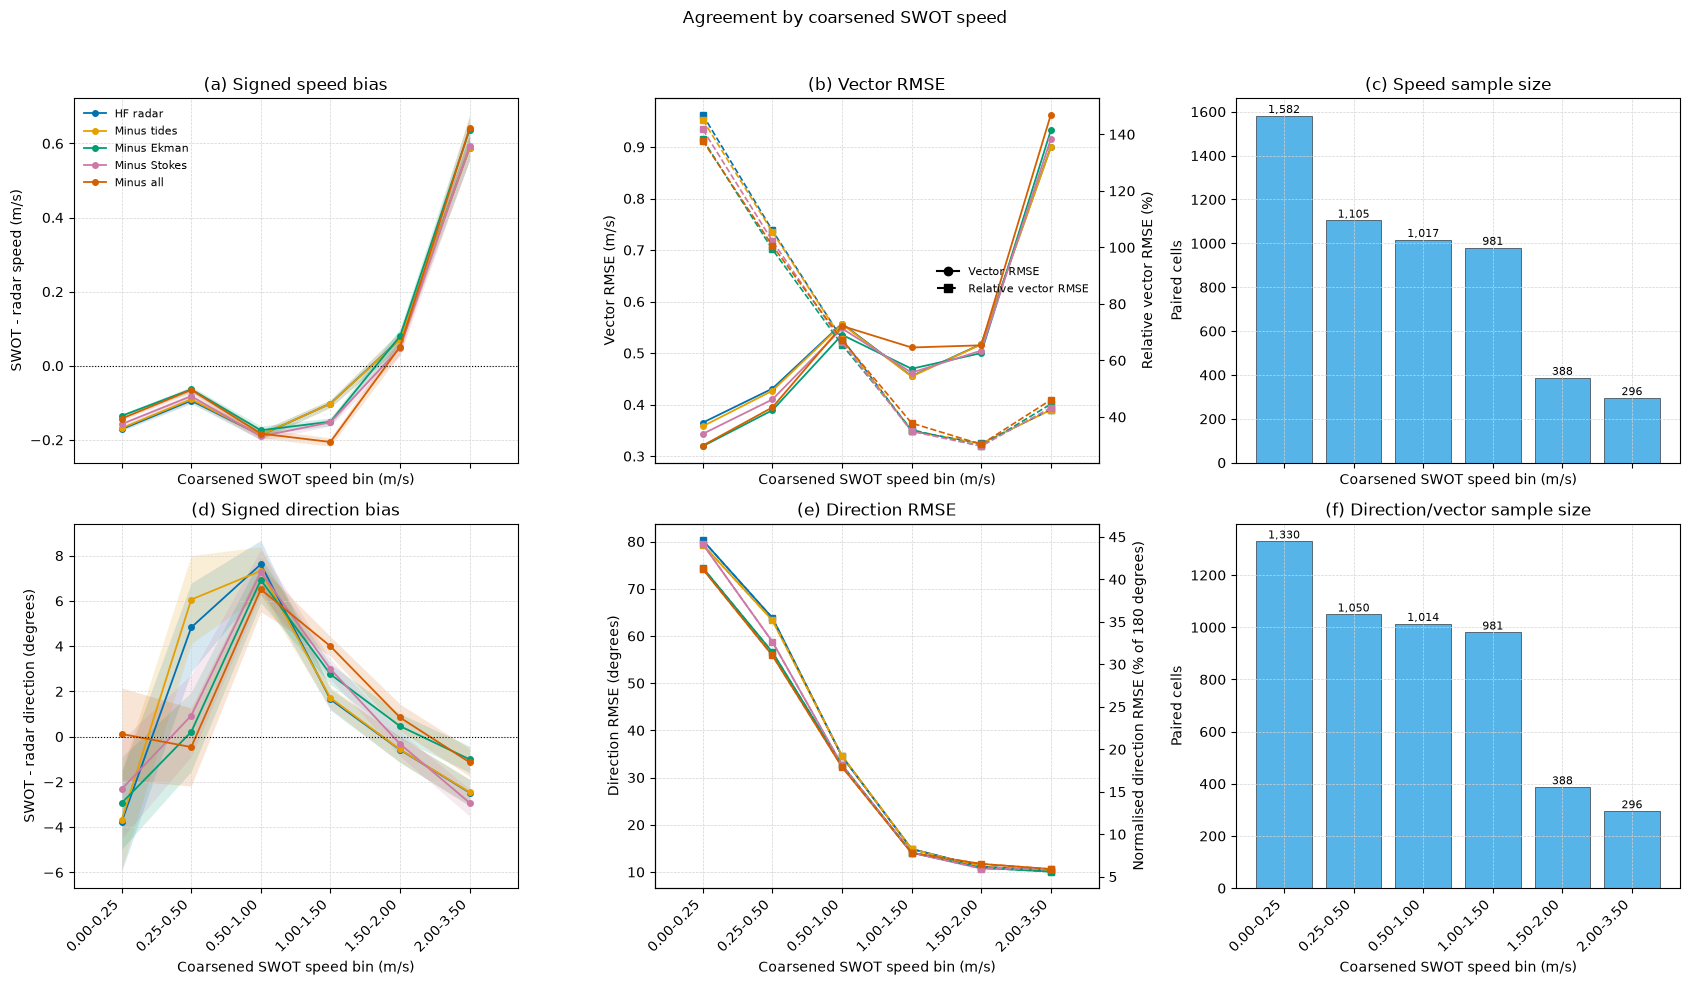

Speed pairs in bins (identical for all variants): 5,369
Direction/vector pairs in bins (identical for all variants): 5,059
Minus tides: vector RMSE change (m/s) = [-0.007, -0.004, -0.001, -0.001, -0.001, -0.001], direction RMSE change (deg) = [-0.9, -0.5, 0.1, -0.0, -0.0, -0.0]
Minus Ekman: vector RMSE change (m/s) = [-0.046, -0.042, -0.022, 0.014, -0.017, 0.032], direction RMSE change (deg) = [-5.8, -7.3, -1.8, -0.8, -0.2, -0.2]
Minus Stokes: vector RMSE change (m/s) = [-0.022, -0.021, -0.009, 0.007, -0.013, 0.015], direction RMSE change (deg) = [-0.8, -5.0, -1.8, -0.8, -0.4, 0.3]
Minus all: vector RMSE change (m/s) = [-0.045, -0.037, -0.005, 0.055, -0.002, 0.063], direction RMSE change (deg) = [-6.1, -7.9, -2.2, -0.8, 0.6, 0.3]


In [21]:
# Plot the same paired comparison metrics using an alternate speed variable for binning.
def plot_speed_binned_comparison(bin_variable, bin_variable_label, figure_title):
    bin_edges = np.array([0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.5])
    bin_labels = ['0.00-0.25', '0.25-0.50', '0.50-1.00', '1.00-1.50', '1.50-2.00', '2.00-3.50']
    bin_positions = np.arange(len(bin_labels))
    speed_counts = np.zeros(len(bin_labels), dtype=int)
    vector_counts = np.zeros(len(bin_labels), dtype=int)
    bin_metrics = {
        label: {name: np.full(len(bin_labels), np.nan) for name in (
            'speed_bias', 'speed_sem', 'vector_rmse', 'relative_vector_rmse',
            'direction_bias', 'direction_sem', 'direction_rmse', 'direction_relative_rmse',
        )}
        for label in variants
    }

    for bin_index in range(len(bin_labels)):
        in_bin = (bin_variable >= bin_edges[bin_index]) & (
            (bin_variable <= bin_edges[bin_index + 1]) if bin_index == len(bin_labels) - 1
            else (bin_variable < bin_edges[bin_index + 1])
        )
        speed_valid = paired_mask & in_bin
        vector_valid = vector_mask & in_bin
        speed_counts[bin_index] = int(speed_valid.sum())
        vector_counts[bin_index] = int(vector_valid.sum())

        for label, (variant_u, variant_v) in variants.items():
            variant_speed = np.hypot(variant_u, variant_v)
            values = bin_metrics[label]
            if speed_counts[bin_index]:
                speed_error = swot_speed[speed_valid] - variant_speed[speed_valid]
                values['speed_bias'][bin_index] = np.mean(speed_error)
                if speed_counts[bin_index] > 1:
                    values['speed_sem'][bin_index] = np.std(speed_error, ddof=1) / np.sqrt(speed_counts[bin_index])
            if not vector_counts[bin_index]:
                continue
            squared_error = (swot_u[vector_valid] - variant_u[vector_valid]) ** 2 + (
                swot_v[vector_valid] - variant_v[vector_valid]
            ) ** 2
            values['vector_rmse'][bin_index] = np.sqrt(np.mean(squared_error))
            reference_speed = (swot_speed[vector_valid] + variant_speed[vector_valid]) / 2
            values['relative_vector_rmse'][bin_index] = (
                100 * values['vector_rmse'][bin_index] / np.mean(reference_speed)
            )
            variant_direction = np.degrees(np.arctan2(variant_v[vector_valid], variant_u[vector_valid]))
            direction_error = ((swot_direction[vector_valid] - variant_direction + 180) % 360) - 180
            values['direction_bias'][bin_index] = np.mean(direction_error)
            values['direction_rmse'][bin_index] = np.sqrt(np.mean(direction_error ** 2))
            values['direction_relative_rmse'][bin_index] = 100 * values['direction_rmse'][bin_index] / 180
            if vector_counts[bin_index] > 1:
                values['direction_sem'][bin_index] = np.std(direction_error, ddof=1) / np.sqrt(vector_counts[bin_index])

    figure, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True)
    speed_bias_axis, vector_error_axis, speed_count_axis = axes[0]
    direction_bias_axis, direction_error_axis, vector_count_axis = axes[1]
    relative_vector_axis = vector_error_axis.twinx()
    direction_relative_axis = direction_error_axis.twinx()

    for label, values in bin_metrics.items():
        colour = variant_colours[label]
        speed_bias_axis.plot(bin_positions, values['speed_bias'], 'o-',
                             color=colour, linewidth=1.3, markersize=4, label=label)
        speed_bias_axis.fill_between(
            bin_positions,
            values['speed_bias'] - values['speed_sem'],
            values['speed_bias'] + values['speed_sem'],
            color=colour, alpha=0.16, linewidth=0,
        )
        vector_error_axis.plot(
            bin_positions, values['vector_rmse'], 'o-', color=colour, linewidth=1.3, markersize=4,
        )
        relative_vector_axis.plot(
            bin_positions, values['relative_vector_rmse'], 's--', color=colour,
            linewidth=1.2, markersize=4,
        )
        direction_bias_axis.plot(
            bin_positions, values['direction_bias'], 'o-', color=colour, linewidth=1.3, markersize=4,
        )
        direction_bias_axis.fill_between(
            bin_positions,
            values['direction_bias'] - values['direction_sem'],
            values['direction_bias'] + values['direction_sem'],
            color=colour, alpha=0.16, linewidth=0,
        )
        direction_error_axis.plot(
            bin_positions, values['direction_rmse'], 'o-', color=colour, linewidth=1.3, markersize=4,
        )
        direction_relative_axis.plot(
            bin_positions, values['direction_relative_rmse'], 's--', color=colour,
            linewidth=1.2, markersize=4,
        )

    speed_bias_axis.axhline(0, color='black', linestyle=':', linewidth=0.8)
    direction_bias_axis.axhline(0, color='black', linestyle=':', linewidth=0.8)
    speed_bias_axis.set_title('(a) Signed speed bias')
    speed_bias_axis.set_ylabel('SWOT - radar speed (m/s)')
    speed_bias_axis.legend(fontsize=8, loc='best', frameon=False)
    vector_error_axis.set_title('(b) Vector RMSE')
    vector_error_axis.set_ylabel('Vector RMSE (m/s)')
    relative_vector_axis.set_ylabel('Relative vector RMSE (%)')
    vector_error_axis.legend(handles=[
        plt.Line2D([], [], color='black', marker='o', label='Vector RMSE'),
        plt.Line2D([], [], color='black', marker='s', linestyle='--', label='Relative vector RMSE'),
    ], loc='center right', fontsize=8, frameon=False)
    speed_count_axis.set_title('(c) Speed sample size')
    speed_count_axis.set_ylabel('Paired cells')
    direction_bias_axis.set_title('(d) Signed direction bias')
    direction_bias_axis.set_ylabel('SWOT - radar direction (degrees)')
    direction_error_axis.set_title('(e) Direction RMSE')
    direction_error_axis.set_ylabel('Direction RMSE (degrees)')
    direction_relative_axis.set_ylabel('Normalised direction RMSE (% of 180 degrees)')
    vector_count_axis.set_title('(f) Direction/vector sample size')
    vector_count_axis.set_ylabel('Paired cells')

    for axis, counts in ((speed_count_axis, speed_counts), (vector_count_axis, vector_counts)):
        axis.bar(bin_positions, counts, width=0.8, color='#56B4E9', edgecolor='#343a40', linewidth=0.5)
        for position, count in zip(bin_positions, counts):
            if count:
                axis.text(position, count, f'{count:,}', ha='center', va='bottom', fontsize=8)
    for axis in axes.ravel():
        axis.set_xticks(bin_positions)
        axis.set_xticklabels(bin_labels, rotation=45, ha='right')
        axis.set_xlabel(bin_variable_label)
        axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)

    figure.suptitle(figure_title)
    figure.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    print(f'Speed pairs in bins (identical for all variants): {speed_counts.sum():,}')
    print(f'Direction/vector pairs in bins (identical for all variants): {vector_counts.sum():,}')
    for label, values in bin_metrics.items():
        if label == 'HF radar':
            continue
        vector_change = values['vector_rmse'] - bin_metrics['HF radar']['vector_rmse']
        direction_change = values['direction_rmse'] - bin_metrics['HF radar']['direction_rmse']
        print(f'{label}: vector RMSE change (m/s) = {np.round(vector_change, 3).tolist()}, '
              f'direction RMSE change (deg) = {np.round(direction_change, 1).tolist()}')
    return bin_metrics, speed_counts, vector_counts


swot_speed_binned_metrics, swot_speed_bin_counts, swot_speed_vector_counts = plot_speed_binned_comparison(
    swot_speed,
    'Coarsened SWOT speed bin (m/s)',
    'Agreement by coarsened SWOT speed',
)

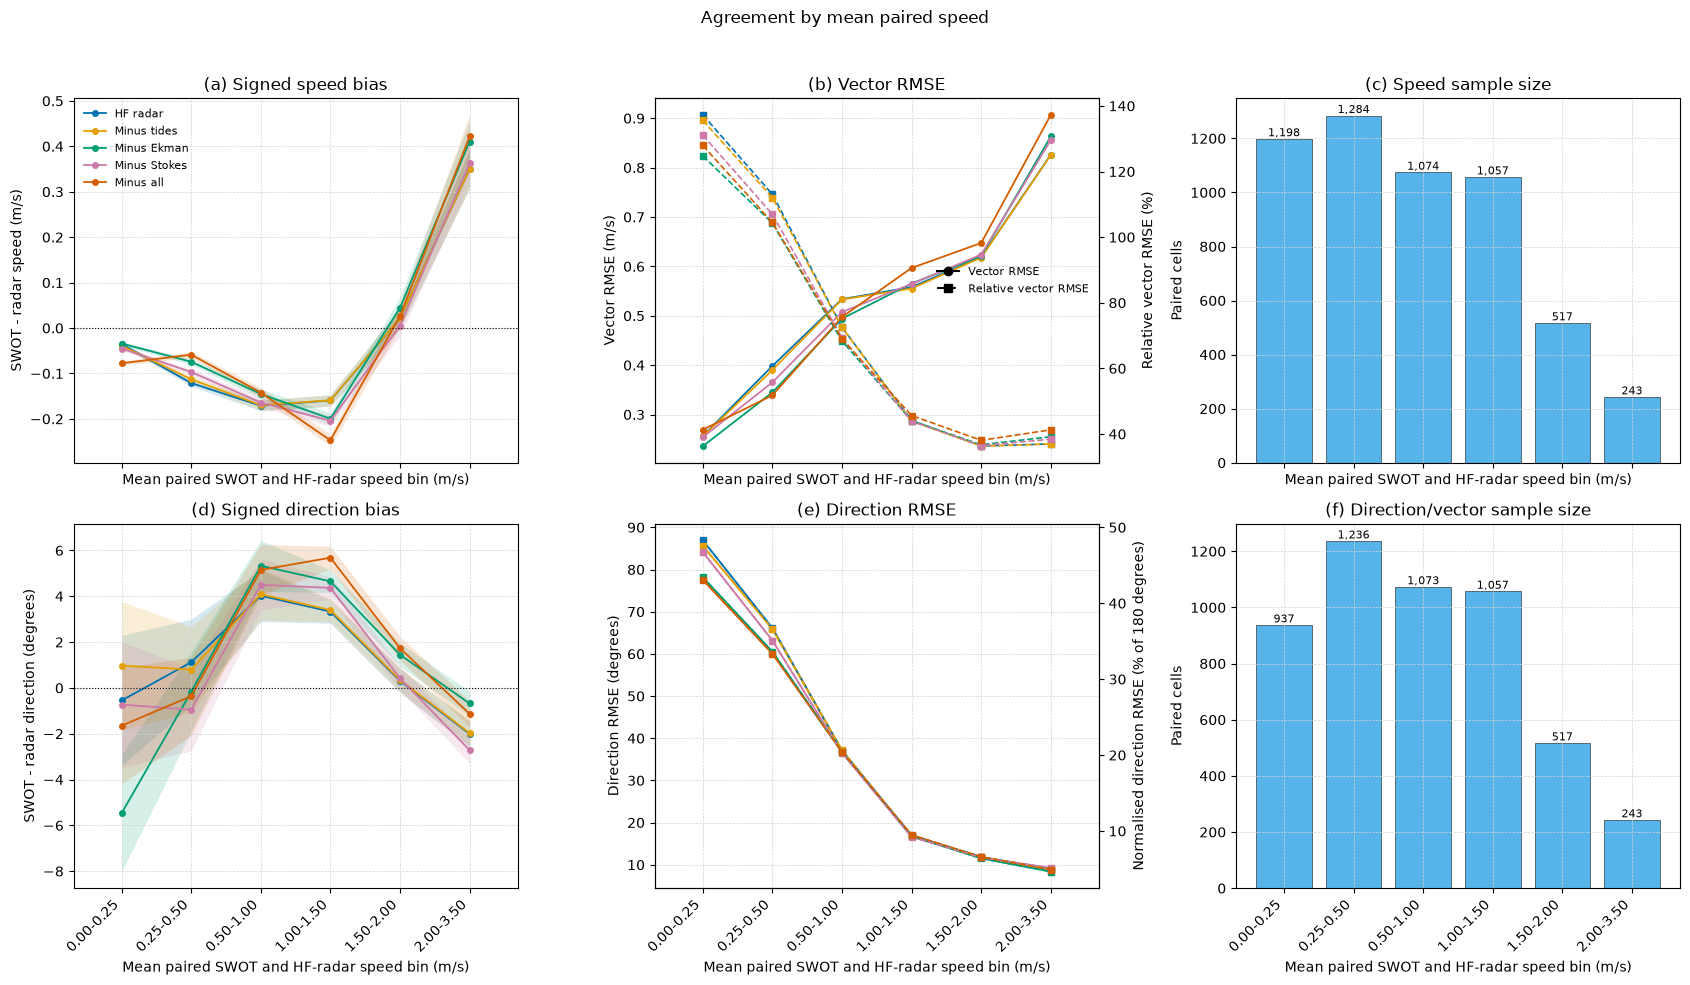

Speed pairs in bins (identical for all variants): 5,373
Direction/vector pairs in bins (identical for all variants): 5,063
Minus tides: vector RMSE change (m/s) = [-0.0, -0.008, -0.001, -0.003, -0.001, -0.001], direction RMSE change (deg) = [-1.3, -0.2, 0.1, -0.0, -0.0, -0.0]
Minus Ekman: vector RMSE change (m/s) = [-0.02, -0.054, -0.04, 0.007, 0.002, 0.037], direction RMSE change (deg) = [-8.7, -5.6, -0.3, -0.1, -0.3, -0.6]
Minus Stokes: vector RMSE change (m/s) = [-0.002, -0.033, -0.026, 0.006, 0.005, 0.03], direction RMSE change (deg) = [-2.8, -3.0, -0.5, -0.3, -0.1, 0.3]
Minus all: vector RMSE change (m/s) = [0.013, -0.06, -0.036, 0.039, 0.028, 0.081], direction RMSE change (deg) = [-9.4, -6.1, -0.3, 0.2, 0.0, -0.1]


In [22]:
# Repeat the paired comparison with bins defined by the mean SWOT/HF-radar speed.
mean_pair_speed = 0.5 * (swot_speed + radar_speed)
mean_speed_binned_metrics, mean_speed_bin_counts, mean_speed_vector_counts = plot_speed_binned_comparison(
    mean_pair_speed,
    'Mean paired SWOT and HF-radar speed bin (m/s)',
    'Agreement by mean paired speed',
)

In [23]:
from pathlib import Path

from IPython.display import display
import numpy as np
import pandas as pd
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
matched_path = repo_root / 'data/processed/swot_hfradar_zarr_matches.zarr'
minimum_direction_speed = 0.05

with xr.open_zarr(matched_path, consolidated=True, chunks=None) as matched_ds:
    swot_u = matched_ds.ugos_coarsened_masked.values
    swot_v = matched_ds.vgos_coarsened_masked.values
    radar_u = matched_ds.ewct_masked.values
    radar_v = matched_ds.nsct_masked.values
    comparison_mask = matched_ds.comparison_mask.values
    corrections = {
        component: (matched_ds[f'{component}_u_masked'].values,
                    matched_ds[f'{component}_v_masked'].values)
        for component in ('tide', 'ekman', 'stokes')
    }

radar_variants = {
    'HF radar': (radar_u, radar_v),
    'HF radar - tides': (radar_u - corrections['tide'][0], radar_v - corrections['tide'][1]),
    'HF radar - Ekman': (radar_u - corrections['ekman'][0], radar_v - corrections['ekman'][1]),
    'HF radar - Stokes': (radar_u - corrections['stokes'][0], radar_v - corrections['stokes'][1]),
    'HF radar - all': (
        radar_u - sum(values[0] for values in corrections.values()),
        radar_v - sum(values[1] for values in corrections.values()),
    ),
}

paired_mask = comparison_mask & np.isfinite(swot_u) & np.isfinite(swot_v)
for variant_u, variant_v in radar_variants.values():
    paired_mask &= np.isfinite(variant_u) & np.isfinite(variant_v)
if not paired_mask.any():
    raise ValueError('No complete SWOT/HF-radar comparisons are available.')

swot_speed = np.hypot(swot_u, swot_v)
direction_mask = paired_mask & (swot_speed >= minimum_direction_speed)
for variant_u, variant_v in radar_variants.values():
    direction_mask &= np.hypot(variant_u, variant_v) >= minimum_direction_speed
if not direction_mask.any():
    raise ValueError('No common pairs meet the direction speed threshold.')

swot_direction = np.degrees(np.arctan2(swot_v, swot_u))
global_rows = []
for label, (variant_u, variant_v) in radar_variants.items():
    variant_speed = np.hypot(variant_u, variant_v)
    speed_error = swot_speed[paired_mask] - variant_speed[paired_mask]
    u_error = swot_u[paired_mask] - variant_u[paired_mask]
    v_error = swot_v[paired_mask] - variant_v[paired_mask]
    variant_direction = np.degrees(np.arctan2(variant_v, variant_u))
    direction_error = (
        (swot_direction[direction_mask] - variant_direction[direction_mask] + 180.0) % 360.0
    ) - 180.0
    error_radians = np.radians(direction_error)
    mean_sine = np.mean(np.sin(error_radians))
    mean_cosine = np.mean(np.cos(error_radians))
    resultant_length = np.hypot(mean_sine, mean_cosine)
    global_rows.append({
        'Radar variant': label,
        'Speed pairs': int(paired_mask.sum()),
        'Speed bias (m/s)': float(np.mean(speed_error)),
        'Speed MAE (m/s)': float(np.mean(np.abs(speed_error))),
        'Speed RMSE (m/s)': float(np.sqrt(np.mean(speed_error ** 2))),
        'Speed r': float(np.corrcoef(swot_speed[paired_mask], variant_speed[paired_mask])[0, 1]),
        'Vector RMSE (m/s)': float(np.sqrt(np.mean(u_error ** 2 + v_error ** 2))),
        'Direction pairs': int(direction_mask.sum()),
        'Direction circular bias (deg)': float(np.degrees(np.arctan2(mean_sine, mean_cosine))),
        'Direction MAE (deg)': float(np.mean(np.abs(direction_error))),
        'Direction RMSE (deg)': float(np.sqrt(np.mean(direction_error ** 2))),
        'Direction circular spread (deg)': (
            float(np.degrees(np.sqrt(-2.0 * np.log(resultant_length))))
            if resultant_length > 0 else np.nan
        ),
    })

global_stats = pd.DataFrame(global_rows).set_index('Radar variant')
print('SWOT minus HF-radar variant; pooled matched cells across all overpasses.')
print(f'Direction requires every variant and SWOT to exceed {minimum_direction_speed:g} m/s.')
display(global_stats.round(3))

SWOT minus HF-radar variant; pooled matched cells across all overpasses.
Direction requires every variant and SWOT to exceed 0.05 m/s.


,Speed pairs,Speed bias (m/s),Speed MAE (m/s),Speed RMSE (m/s),Speed r,Vector RMSE (m/s),Direction pairs,Direction circular bias (deg),Direction MAE (deg),Direction RMSE (deg),Direction circular spread (deg)
Radar variant,,,,,,,,,,,
HF radar,5373,-0.084,0.275,0.384,0.826,0.489,5063,1.990,33.703,53.233,47.540
HF radar - tides,5373,-0.083,0.273,0.381,0.828,0.487,5063,2.274,33.500,52.776,47.282
HF radar - Ekman,5373,-0.071,0.263,0.378,0.831,0.473,5063,2.765,30.645,48.853,43.644
HF radar - Stokes,5373,-0.089,0.268,0.381,0.832,0.481,5063,1.963,32.268,51.404,45.900
HF radar - all,5373,-0.087,0.278,0.396,0.820,0.491,5063,3.605,30.676,48.551,43.520


Table S2. Pooled comparison statistics for HF-radar velocities and variants corrected by subtracting tides, Ekman currents, Stokes drift, or all three, relative to coarsened SWOT velocities across the matched overpasses. Speed metrics use the common set of valid paired grid cells; direction metrics use the common subset where SWOT and every radar variant have speeds greater than 0.05 m s⁻¹. Bias is defined as SWOT minus the radar variant. Directional bias and spread are circular statistics.

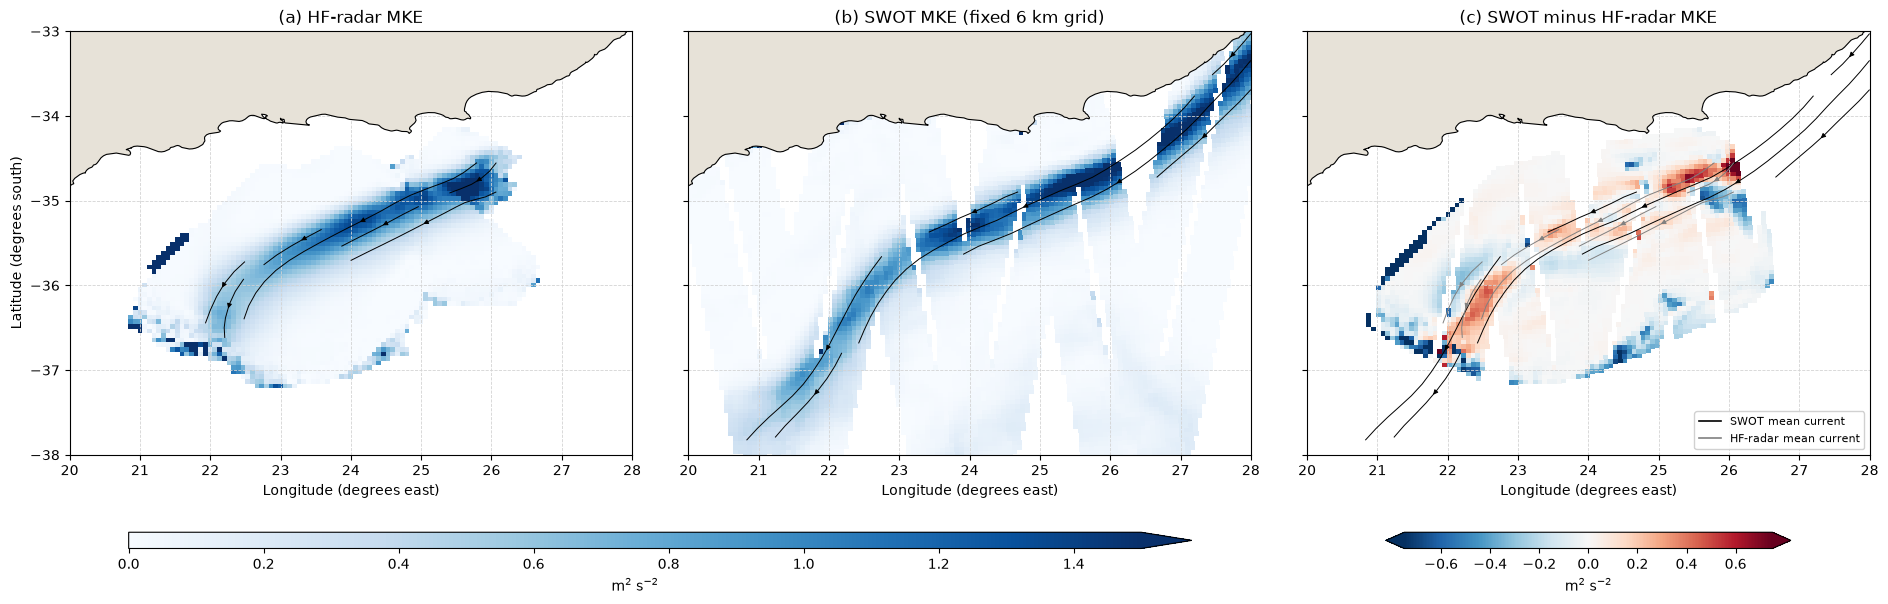

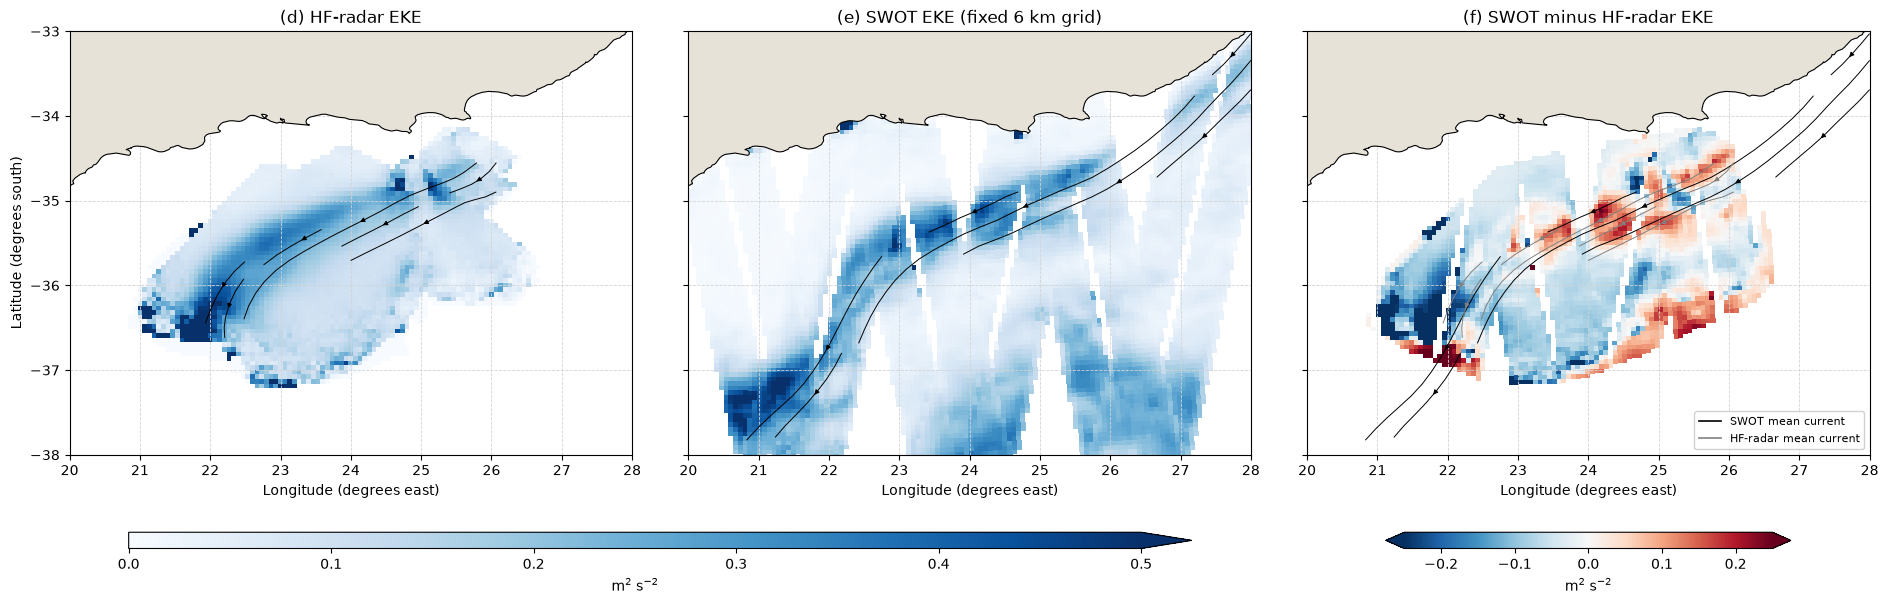

In [25]:
# Compare HF-radar fields with SWOT MKE/EKE calculated directly on the fixed 6 km grid.
# HF fields are evaluated on the SWOT grid only for the difference panels; SWOT NaNs
# remain NaN and are never filled by nearest-neighbour extrapolation.

import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from shapely.geometry import box

with xr.open_zarr(zarr_path, consolidated=True, chunks=None) as hf_ke_ds:
    hf_lon2d, hf_lat2d = np.meshgrid(hf_ke_ds.longitude.values, hf_ke_ds.latitude.values)
    if {"mke", "eke", "u_mean", "v_mean"}.issubset(hf_ke_ds.data_vars):
        hf_mke = hf_ke_ds["mke"].values
        hf_eke = hf_ke_ds["eke"].values
        hf_u_mean = hf_ke_ds["u_mean"].values
        hf_v_mean = hf_ke_ds["v_mean"].values
    else:
        hf_u_sum = np.zeros(hf_lon2d.shape, dtype=float)
        hf_v_sum = np.zeros(hf_lon2d.shape, dtype=float)
        hf_u_squared_sum = np.zeros(hf_lon2d.shape, dtype=float)
        hf_v_squared_sum = np.zeros(hf_lon2d.shape, dtype=float)
        hf_count = np.zeros(hf_lon2d.shape, dtype=np.int64)
        for start in range(0, hf_ke_ds.sizes["time"], 128):
            time_slice = slice(start, start + 128)
            u_chunk = hf_ke_ds["ewct"].isel(time=time_slice).values
            v_chunk = hf_ke_ds["nsct"].isel(time=time_slice).values
            valid_chunk = np.isfinite(u_chunk) & np.isfinite(v_chunk)
            u_valid = np.where(valid_chunk, u_chunk, 0)
            v_valid = np.where(valid_chunk, v_chunk, 0)
            hf_u_sum += u_valid.sum(axis=0)
            hf_v_sum += v_valid.sum(axis=0)
            hf_u_squared_sum += (u_valid ** 2).sum(axis=0)
            hf_v_squared_sum += (v_valid ** 2).sum(axis=0)
            hf_count += valid_chunk.sum(axis=0)
        hf_u_mean = np.divide(hf_u_sum, hf_count, out=np.full_like(hf_u_sum, np.nan), where=hf_count > 0)
        hf_v_mean = np.divide(hf_v_sum, hf_count, out=np.full_like(hf_v_sum, np.nan), where=hf_count > 0)
        hf_mke = 0.5 * (hf_u_mean ** 2 + hf_v_mean ** 2)
        mean_squared_speed = np.divide(
            hf_u_squared_sum + hf_v_squared_sum,
            hf_count,
            out=np.full_like(hf_u_sum, np.nan),
            where=hf_count > 0,
        )
        hf_eke = 0.5 * np.maximum(mean_squared_speed - hf_u_mean ** 2 - hf_v_mean ** 2, 0)

with xr.open_zarr(swot_out_zarr_path, consolidated=True) as swot_archive:
    swot_ke_ds_loaded = swot_archive[["mke", "eke", "grid_latitude", "grid_longitude"]]
    swot_lon2d = swot_ke_ds_loaded["grid_longitude"].values
    swot_lat2d = swot_ke_ds_loaded["grid_latitude"].values
    swot_mke = swot_ke_ds_loaded["mke"].values
    swot_eke = swot_ke_ds_loaded["eke"].values
    if {"u_mean", "v_mean"}.issubset(swot_archive.data_vars):
        swot_u_mean = swot_archive["u_mean"].values
        swot_v_mean = swot_archive["v_mean"].values
    else:
        swot_u_mean = np.full((n_y, n_x), np.nan, dtype="float32")
        swot_v_mean = np.full((n_y, n_x), np.nan, dtype="float32")
        swot_u_sum = np.zeros((n_y, n_x), dtype="float64")
        swot_v_sum = np.zeros((n_y, n_x), dtype="float64")
        swot_vector_count = np.zeros((n_y, n_x), dtype="int32")
        swot_cell_ids = np.stack(
            [
                grid_cell_ids(
                    swot_out_ds.longitude.isel(time=time_index).compute().values,
                    swot_out_ds.latitude.isel(time=time_index).compute().values,
                )
                for time_index in range(swot_out_ds.sizes["time"])
            ]
        )
        for time_index in range(swot_out_ds.sizes["time"]):
            u_values = swot_out_ds["ugos_filtered"].isel(time=time_index).compute().values.ravel()
            v_values = swot_out_ds["vgos_filtered"].isel(time=time_index).compute().values.ravel()
            cell_ids = swot_cell_ids[time_index]
            valid = np.isfinite(u_values) & np.isfinite(v_values) & (cell_ids >= 0)
            if valid.any():
                valid_cells = cell_ids[valid]
                swot_u_sum += np.bincount(
                    valid_cells,
                    weights=u_values[valid],
                    minlength=n_y * n_x,
                ).reshape(n_y, n_x)
                swot_v_sum += np.bincount(
                    valid_cells,
                    weights=v_values[valid],
                    minlength=n_y * n_x,
                ).reshape(n_y, n_x)
                swot_vector_count += np.bincount(
                    valid_cells,
                    minlength=n_y * n_x,
                ).reshape(n_y, n_x)
        valid_mean = swot_vector_count > 0
        swot_u_mean[valid_mean] = (swot_u_sum[valid_mean] / swot_vector_count[valid_mean]).astype("float32")
        swot_v_mean[valid_mean] = (swot_v_sum[valid_mean] / swot_vector_count[valid_mean]).astype("float32")

land_path = repo_root / "data/raw/basemaps/ne_10m_land.zip"
land = gpd.read_file(land_path).clip(box(lon_min, lat_min, lon_max, lat_max))


def evaluate_hf_on_swot_grid(source_values):
    """Linearly evaluate HF values on the fixed SWOT grid, leaving gaps as NaN."""
    valid = np.isfinite(hf_lon2d) & np.isfinite(hf_lat2d) & np.isfinite(source_values)
    return griddata(
        np.column_stack((hf_lon2d[valid], hf_lat2d[valid])),
        source_values[valid],
        (swot_lon2d, swot_lat2d),
        method="linear",
    ).astype("float32")


def regularise_vectors(longitude, latitude, u_velocity, v_velocity):
    """Interpolate vector components onto a regular plotting grid."""
    valid = (
        np.isfinite(longitude)
        & np.isfinite(latitude)
        & np.isfinite(u_velocity)
        & np.isfinite(v_velocity)
    )
    regular_longitude = np.linspace(lon_min, lon_max, 80)
    regular_latitude = np.linspace(lat_min, lat_max, 60)
    regular_lon2d, regular_lat2d = np.meshgrid(regular_longitude, regular_latitude)
    points = np.column_stack((longitude[valid], latitude[valid]))
    regular_u = griddata(points, u_velocity[valid], (regular_lon2d, regular_lat2d), method="linear")
    regular_v = griddata(points, v_velocity[valid], (regular_lon2d, regular_lat2d), method="linear")
    speed = np.hypot(regular_u, regular_v)
    regular_u[speed <= 0.75] = np.nan
    regular_v[speed <= 0.75] = np.nan
    return regular_longitude, regular_latitude, regular_u, regular_v


hf_mke_on_swot = evaluate_hf_on_swot_grid(hf_mke)
hf_eke_on_swot = evaluate_hf_on_swot_grid(hf_eke)
mke_diff = swot_mke - hf_mke_on_swot
eke_diff = swot_eke - hf_eke_on_swot
hf_streamline_grid = regularise_vectors(hf_lon2d, hf_lat2d, hf_u_mean, hf_v_mean)
swot_streamline_grid = (
    streamline_longitude,
    streamline_latitude,
    stream_u,
    stream_v,
)


def plot_energy_row(fields, titles, energy_limits, difference_limits):
    """Plot energy fields with thresholded mean-flow streamlines."""
    figure, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)
    panel_data = [
        (fields[0], hf_lon2d, hf_lat2d, titles[0], "Blues", energy_limits, hf_streamline_grid),
        (fields[1], swot_lon2d, swot_lat2d, titles[1], "Blues", energy_limits, swot_streamline_grid),
        (fields[2], swot_lon2d, swot_lat2d, titles[2], "RdBu_r", difference_limits, swot_streamline_grid),
    ]

    for panel_index, (axis, (field, longitude, latitude, title, cmap, limits, streamline_grid)) in enumerate(
        zip(axes, panel_data)
    ):
        land.plot(ax=axis, color="#e7e2d8", zorder=2)
        land.boundary.plot(ax=axis, color="black", linewidth=0.8, zorder=3)
        axis.pcolormesh(
            longitude,
            latitude,
            field,
            cmap=cmap,
            vmin=limits[0],
            vmax=limits[1],
            shading="auto",
            zorder=1,
        )
        stream_longitude, stream_latitude, stream_u, stream_v = streamline_grid
        axis.streamplot(
            stream_longitude,
            stream_latitude,
            stream_u,
            stream_v,
            color="black",
            linewidth=0.7,
            density=1.0,
            arrowsize=0.7,
            zorder=4,
        )
        if panel_index == 2:
            hf_stream_longitude, hf_stream_latitude, hf_stream_u, hf_stream_v = hf_streamline_grid
            axis.streamplot(
                hf_stream_longitude,
                hf_stream_latitude,
                hf_stream_u,
                hf_stream_v,
                color="grey",
                linewidth=0.7,
                density=1.0,
                arrowsize=0.7,
                zorder=4,
            )
            axis.legend(
                handles=[
                    plt.Line2D([], [], color="black", linewidth=1.2, label="SWOT mean current"),
                    plt.Line2D([], [], color="grey", linewidth=1.2, label="HF-radar mean current"),
                ],
                loc="lower right",
                fontsize=8,
                framealpha=0.9,
            )
        axis.set_xlim(lon_min, lon_max)
        axis.set_ylim(lat_min, lat_max)
        axis.set_title(title)
        axis.set_xlabel("Longitude (degrees east)")
        axis.grid(color="lightgrey", linestyle="--", linewidth=0.6)

    axes[0].set_ylabel("Latitude (degrees south)")
    figure.subplots_adjust(
        left=0.05,
        right=0.95,
        bottom=0.20,
        top=0.88,
        wspace=0.10,
    )

    first_axis_position = axes[0].get_position()
    second_axis_position = axes[1].get_position()
    difference_axis_position = axes[2].get_position()
    magnitude_span_left = first_axis_position.x0
    magnitude_span_right = second_axis_position.x1
    magnitude_span_width = magnitude_span_right - magnitude_span_left
    magnitude_width = 0.90 * magnitude_span_width
    magnitude_left = magnitude_span_left + 0.5 * (magnitude_span_width - magnitude_width)
    difference_width = difference_axis_position.width * 0.72
    difference_left = difference_axis_position.x0 + 0.5 * (
        difference_axis_position.width - difference_width
    )
    colourbar_bottom = 0.07
    colourbar_height = 0.025

    magnitude_colourbar_axis = figure.add_axes(
        [magnitude_left, colourbar_bottom, magnitude_width, colourbar_height]
    )
    difference_colourbar_axis = figure.add_axes(
        [difference_left, colourbar_bottom, difference_width, colourbar_height]
    )
    magnitude_mappable = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=energy_limits[0], vmax=energy_limits[1]),
        cmap="Blues",
    )
    difference_mappable = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=difference_limits[0], vmax=difference_limits[1]),
        cmap="RdBu_r",
    )
    figure.colorbar(
        magnitude_mappable,
        cax=magnitude_colourbar_axis,
        orientation="horizontal",
        label=r"m$^2$ s$^{-2}$",
        extend="max",
    )
    figure.colorbar(
        difference_mappable,
        cax=difference_colourbar_axis,
        orientation="horizontal",
        label=r"m$^2$ s$^{-2}$",
        extend="both",
    )
    return figure


mke_figure = plot_energy_row(
    (hf_mke, swot_mke, mke_diff),
    ("(a) HF-radar MKE", "(b) SWOT MKE (fixed 6 km grid)", "(c) SWOT minus HF-radar MKE"),
    (0.0, 1.5),
    (-0.75, 0.75),
)
eke_figure = plot_energy_row(
    (hf_eke, swot_eke, eke_diff),
    ("(d) HF-radar EKE", "(e) SWOT EKE (fixed 6 km grid)", "(f) SWOT minus HF-radar EKE"),
    (0.0, 0.5),
    (-0.25, 0.25),
)

plt.show()

Figure 4. Spatial comparison of mean kinetic energy (MKE; top row) and eddy kinetic energy (EKE; bottom row) derived from HF-radar observations (left), SWOT observations on the 6 km HF-radar grid (centre), and their difference (SWOT minus HF-radar; right). Colours show kinetic energy in m² s⁻². Streamlines indicate mean currents exceeding 0.75 m s⁻¹.